In [1]:
import anndata as ad
import numpy as np
import pandas as pd
import SDP_miRNA.dataset
import SDP_miRNA.optimization
import SDP_miRNA.optimization_MOSEK
import SDP_miRNA.correlation
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import igraph as ig
import seaborn as sns

In [2]:
phases = ["All", "G1", "S", "G2M"]

# TotalX Loading

- d = 3, per phase

In [ ]:
# load TotalX HEK data
TX_MF_ind_df = pd.read_csv("../TotalX/HEK293T-Cell-Cycle/Results/ind_MF.csv", index_col=0)
TX_MF_int_df = pd.read_csv("../TotalX/HEK293T-Cell-Cycle/Results/int_MF.csv", index_col=0)
TX_corr_df = pd.read_csv("../TotalX/HEK293T-Cell-Cycle/Results/corr.csv", index_col=0)

In [4]:
# get RNA names
TX_miRNA_names = [x.split('_')[0] for x in TX_MF_ind_df.columns if "All_status" in x]
TX_mRNA_names = TX_MF_ind_df.index.tolist()

In [10]:
# load TotalX MIR222
TX_MIR222_MF_ind_df = pd.read_csv("../SmartSeqTotal-New/HEK/Results/MIR222_TX_ind_MF.csv", index_col=0)
TX_MIR222_MF_int_df = pd.read_csv("../SmartSeqTotal-New/HEK/Results/MIR222_TX_int_MF.csv", index_col=0)
TX_MIR222_corr_df = pd.read_csv("../SmartSeqTotal-New/HEK/Results/MIR222_TX_corr.csv", index_col=0)

# SmartSeqTotal Loading

In [14]:
# load SmartSeqTotal HEK data
ST_MF_ind_df = pd.read_csv("../SmartSeqTotal-New/HEK/Results/ind_MF.csv", index_col=0)
ST_MF_int_df = pd.read_csv("../SmartSeqTotal-New/HEK/Results/int_MF.csv", index_col=0)
ST_corr_df = pd.read_csv("../SmartSeqTotal-New/HEK/Results/corr.csv", index_col=0)

In [15]:
# get RNA names
ST_miRNA_names = [x.split('_')[0] for x in ST_MF_ind_df.columns if "status" in x]
ST_mRNA_names = ST_MF_ind_df.index.tolist()

In [16]:
plt.rcParams.update({'font.size': 16})

# (Single axis) Observed - Recovered Histogram

## Single miRNA: MIR222

### Default

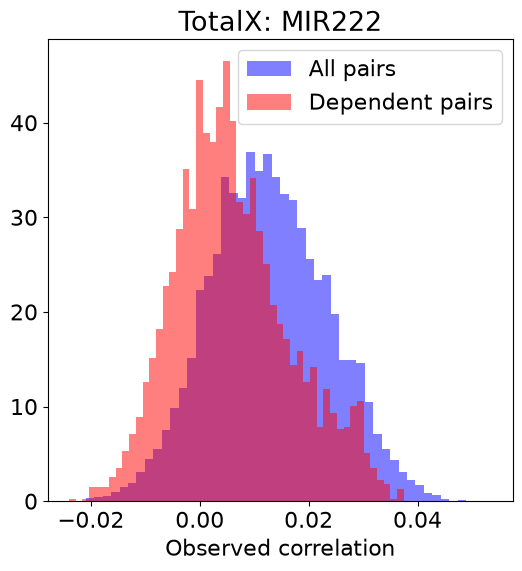

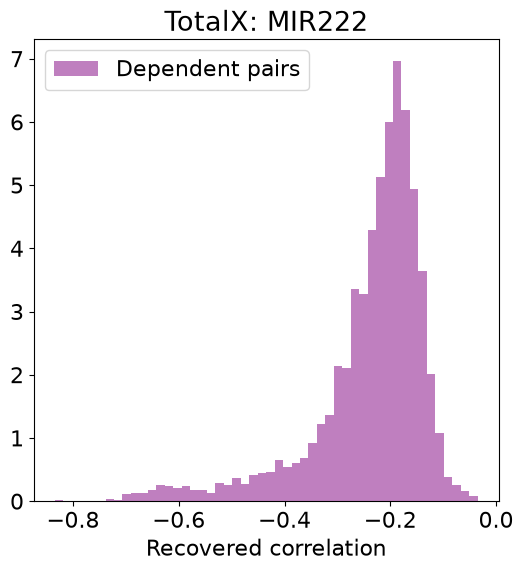

In [85]:
# selection
title = "TotalX: MIR222"
miRNA = "MIR222"
MF_ind_chosen = TX_MIR222_MF_ind_df
MF_int_chosen = TX_MIR222_MF_int_df
corr_chosen = TX_MIR222_corr_df

# data
mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
mid = MF_int_chosen[f'{miRNA}_HAR_mid']
OB = corr_chosen[f'{miRNA}_OB']

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(OB, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs.hist(OB[mask], bins=50, color="red", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Observed correlation")
#axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid[mask], bins=50, color="purple", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Recovered correlation")
#axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

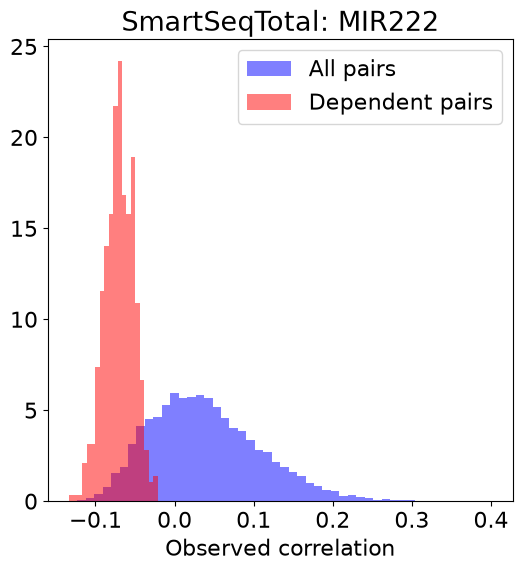

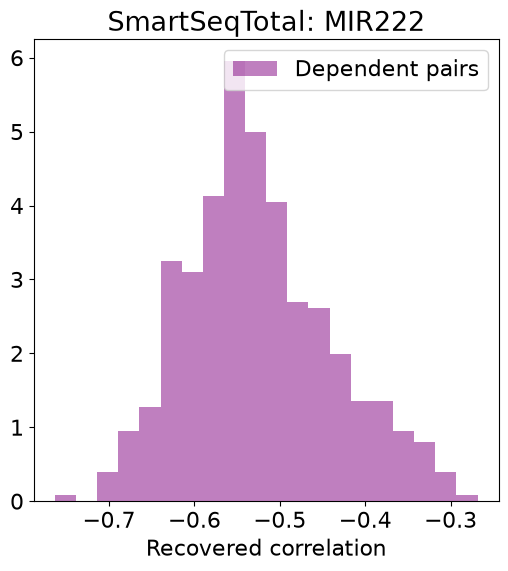

In [86]:
# selection
title = "SmartSeqTotal: MIR222"
miRNA = "MIR222"
MF_ind_chosen = ST_MF_ind_df
MF_int_chosen = ST_MF_int_df
corr_chosen = ST_corr_df

# data
mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
mid = MF_int_chosen[f'{miRNA}_HAR_mid']
OB = corr_chosen[f'{miRNA}_OB']

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(OB, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs.hist(OB[mask], bins=20, color="red", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Observed correlation")
#axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid[mask], bins=20, color="purple", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Recovered correlation")
#axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

### Shared xlim

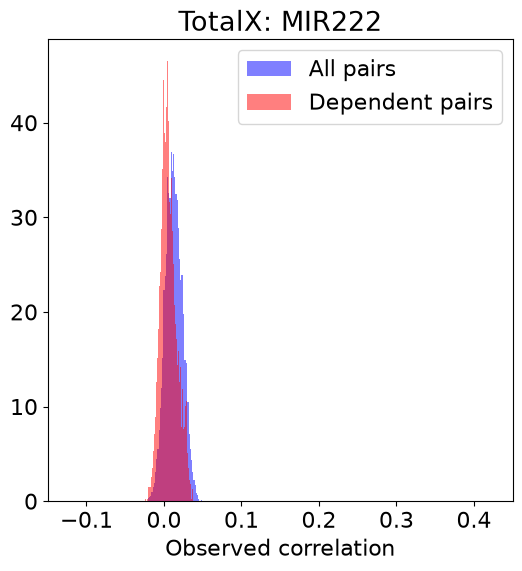

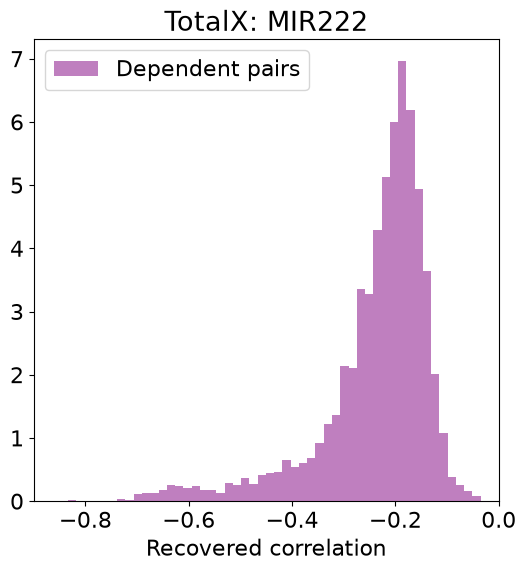

In [87]:
# selection
title = "TotalX: MIR222"
miRNA = "MIR222"
MF_ind_chosen = TX_MIR222_MF_ind_df
MF_int_chosen = TX_MIR222_MF_int_df
corr_chosen = TX_MIR222_corr_df

# data
mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
mid = MF_int_chosen[f'{miRNA}_HAR_mid']
OB = corr_chosen[f'{miRNA}_OB']

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(OB, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs.hist(OB[mask], bins=50, color="red", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Observed correlation")
axs.set_xlim(-0.15, 0.45)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid[mask], bins=50, color="purple", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Recovered correlation")
axs.set_xlim(-0.9, 0.0)

axs.set_title(title)

plt.show()

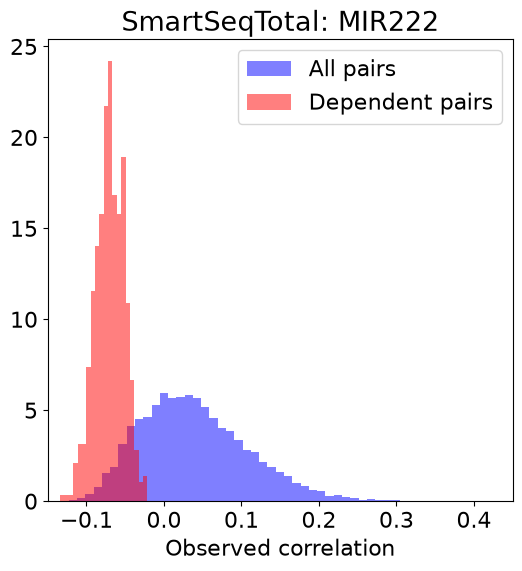

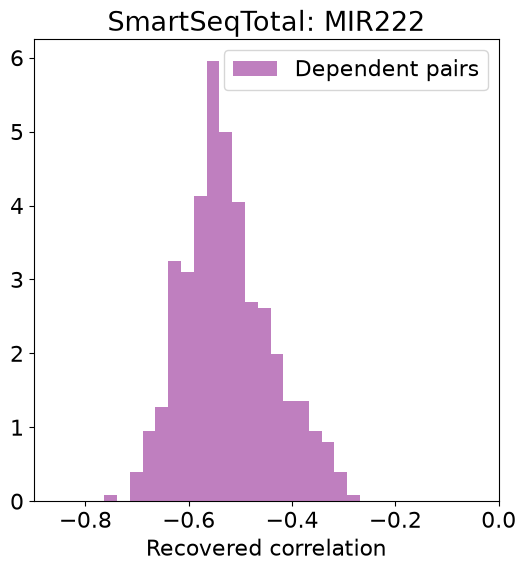

In [89]:
# selection
title = "SmartSeqTotal: MIR222"
miRNA = "MIR222"
MF_ind_chosen = ST_MF_ind_df
MF_int_chosen = ST_MF_int_df
corr_chosen = ST_corr_df

# data
mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
mid = MF_int_chosen[f'{miRNA}_HAR_mid']
OB = corr_chosen[f'{miRNA}_OB']

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(OB, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs.hist(OB[mask], bins=20, color="red", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Observed correlation")
axs.set_xlim(-0.15, 0.45)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid[mask], bins=20, color="purple", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Recovered correlation")
axs.set_xlim(-0.9, 0.0)

axs.set_title(title)

plt.show()

## All miRNA

### Default

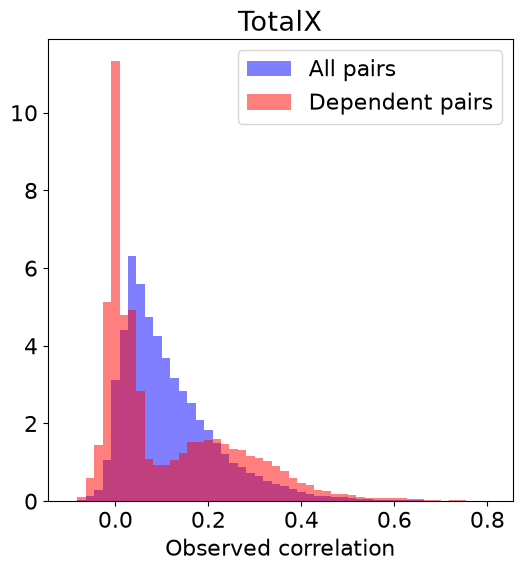

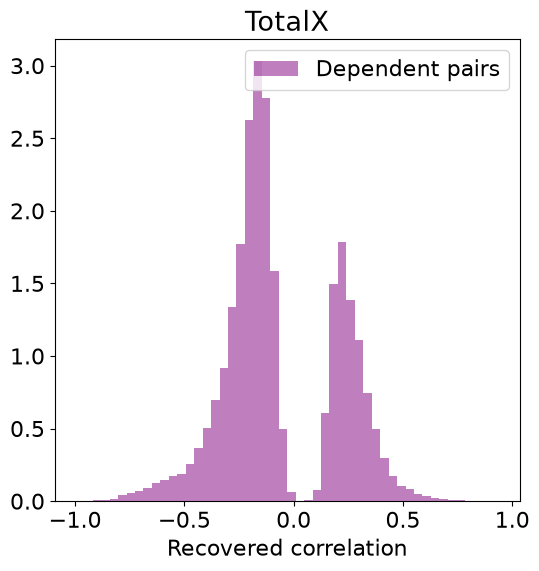

In [90]:
# selection
title = "TotalX"
miRNA_names_chosen = TX_miRNA_names
MF_ind_chosen = TX_MF_ind_df
MF_int_chosen = TX_MF_int_df
corr_chosen = TX_corr_df

# data
OB_all = []
OB_mask_all = []
mid_mask_all = []
for miRNA in miRNA_names_chosen:
    mask = (MF_ind_chosen[f'{miRNA}_All_status'] == "INFEASIBLE").values.squeeze()
    mid = MF_int_chosen[f'{miRNA}_All_HAR_mid']
    OB = corr_chosen[f'{miRNA}_All_OB']
    OB_all += OB.tolist()
    OB_mask_all += OB[mask].tolist()
    mid_mask_all += mid[mask].tolist()

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(OB_all, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs.hist(OB_mask_all, bins=50, color="red", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Observed correlation")
#axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid_mask_all, bins=50, color="purple", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Recovered correlation")
#axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

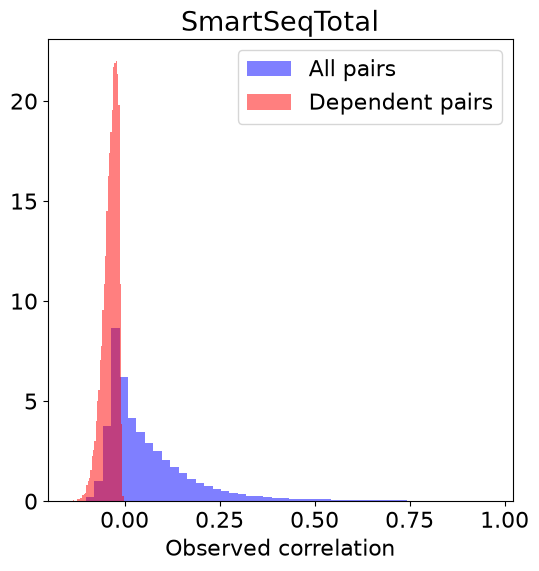

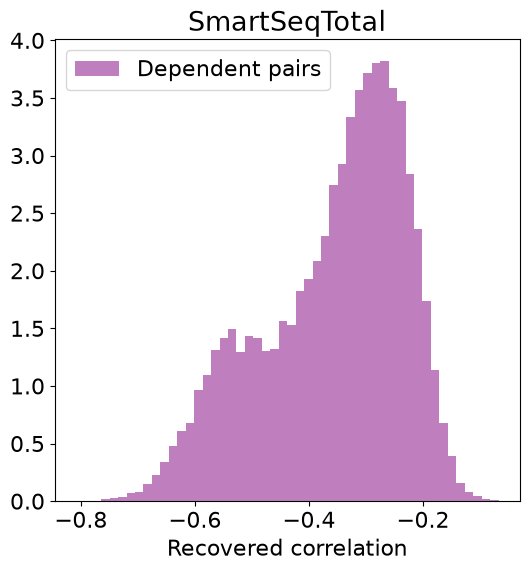

In [91]:
# selection
title = "SmartSeqTotal"
miRNA_names_chosen = ST_miRNA_names
MF_ind_chosen = ST_MF_ind_df
MF_int_chosen = ST_MF_int_df
corr_chosen = ST_corr_df

# data
OB_all = []
OB_mask_all = []
mid_mask_all = []
for miRNA in miRNA_names_chosen:
    mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
    mid = MF_int_chosen[f'{miRNA}_HAR_mid']
    OB = corr_chosen[f'{miRNA}_OB']
    OB_all += OB.tolist()
    OB_mask_all += OB[mask].tolist()
    mid_mask_all += mid[mask].tolist()

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(OB_all, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs.hist(OB_mask_all, bins=50, color="red", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Observed correlation")
#axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid_mask_all, bins=50, color="purple", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Recovered correlation")
#axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

### Shared xlim

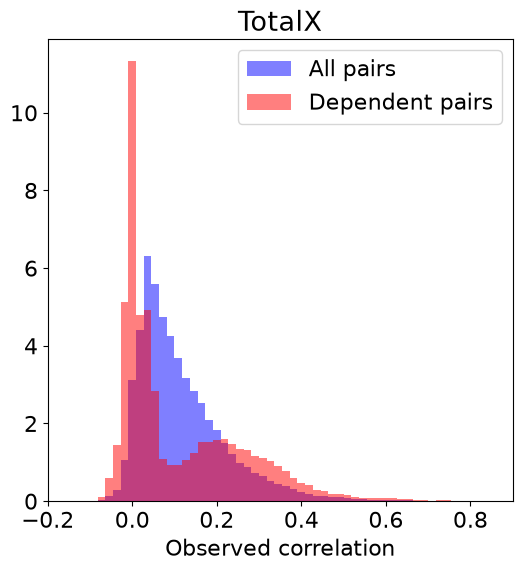

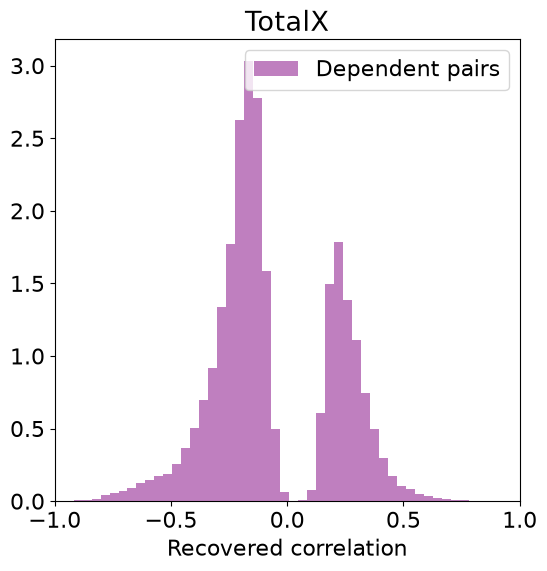

In [92]:
# selection
title = "TotalX"
miRNA_names_chosen = TX_miRNA_names
MF_ind_chosen = TX_MF_ind_df
MF_int_chosen = TX_MF_int_df
corr_chosen = TX_corr_df

# data
OB_all = []
OB_mask_all = []
mid_mask_all = []
for miRNA in miRNA_names_chosen:
    mask = (MF_ind_chosen[f'{miRNA}_All_status'] == "INFEASIBLE").values.squeeze()
    mid = MF_int_chosen[f'{miRNA}_All_HAR_mid']
    OB = corr_chosen[f'{miRNA}_All_OB']
    OB_all += OB.tolist()
    OB_mask_all += OB[mask].tolist()
    mid_mask_all += mid[mask].tolist()

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(OB_all, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs.hist(OB_mask_all, bins=50, color="red", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Observed correlation")
axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid_mask_all, bins=50, color="purple", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Recovered correlation")
axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

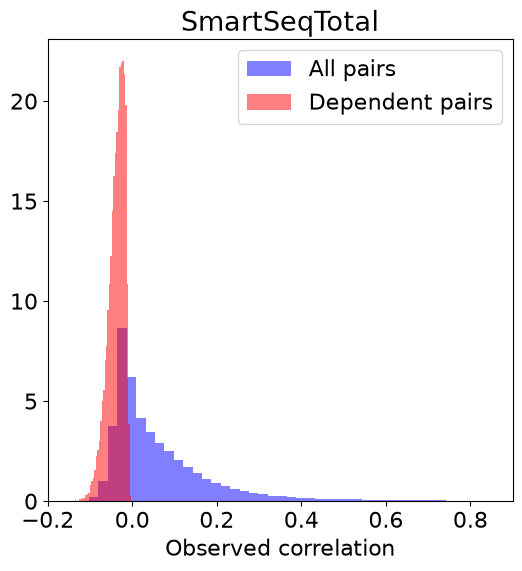

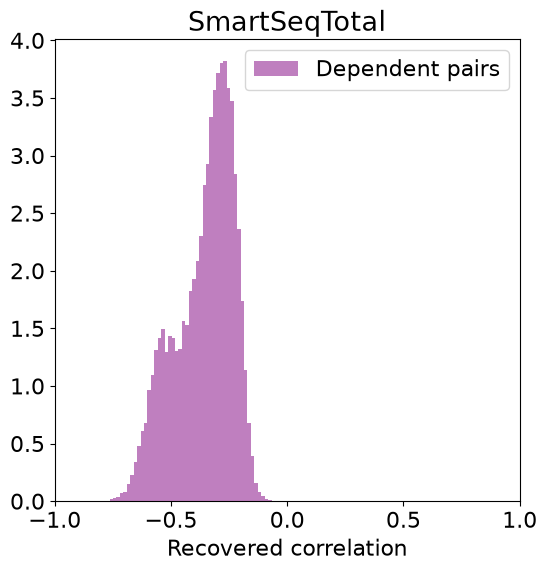

In [93]:
# selection
title = "SmartSeqTotal"
miRNA_names_chosen = ST_miRNA_names
MF_ind_chosen = ST_MF_ind_df
MF_int_chosen = ST_MF_int_df
corr_chosen = ST_corr_df

# data
OB_all = []
OB_mask_all = []
mid_mask_all = []
for miRNA in miRNA_names_chosen:
    mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
    mid = MF_int_chosen[f'{miRNA}_HAR_mid']
    OB = corr_chosen[f'{miRNA}_OB']
    OB_all += OB.tolist()
    OB_mask_all += OB[mask].tolist()
    mid_mask_all += mid[mask].tolist()

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(OB_all, bins=50, color="blue", alpha=0.5, density=True, label="All pairs")
axs.hist(OB_mask_all, bins=50, color="red", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Observed correlation")
axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid_mask_all, bins=50, color="purple", alpha=0.5, density=True, label="Dependent pairs")
axs.legend()

axs.set_xlabel("Recovered correlation")
axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

# (Split axes) Observed - Recovered Histogram

## Single miRNA: MIR222

### Default

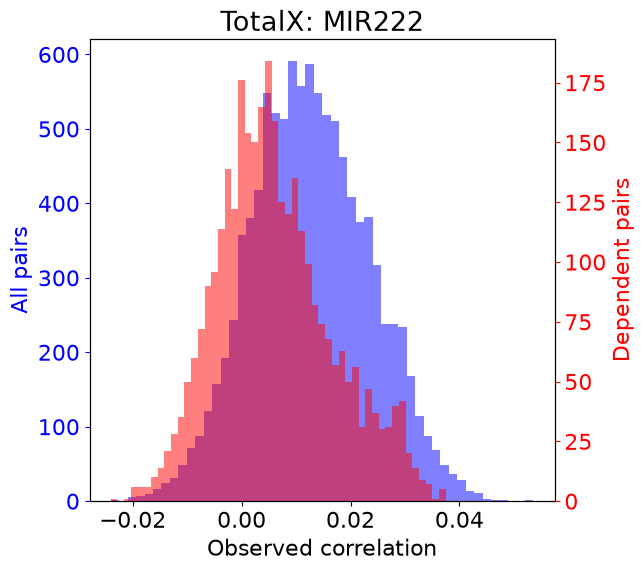

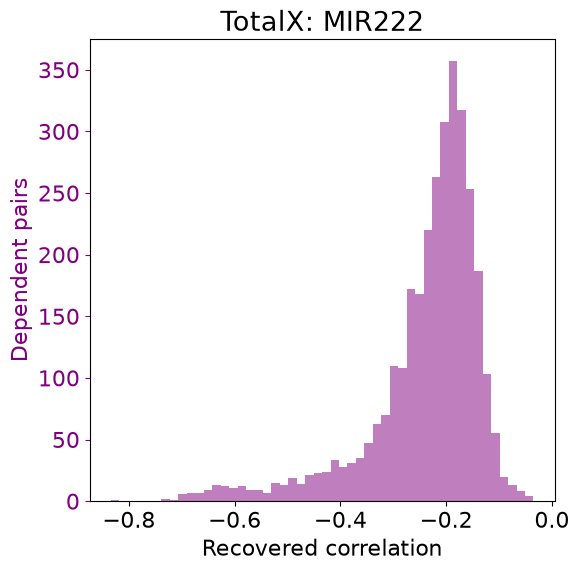

In [52]:
# selection
title = "TotalX: MIR222"
miRNA = "MIR222"
MF_ind_chosen = TX_MIR222_MF_ind_df
MF_int_chosen = TX_MIR222_MF_int_df
corr_chosen = TX_MIR222_corr_df

# data
mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
mid = MF_int_chosen[f'{miRNA}_HAR_mid']
OB = corr_chosen[f'{miRNA}_OB']

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))
axs2 = axs.twinx()

axs.hist(OB, bins=50, color="blue", alpha=0.5, density=False, label="All pairs")
axs.set_ylabel("All pairs", color="blue")
axs.tick_params('y', colors="blue")
#axs.legend()

axs2.hist(OB[mask], bins=50, color="red", alpha=0.5, density=False, label="Dependent pairs")
axs2.set_ylabel("Dependent pairs", color="red")
axs2.tick_params('y', colors="red")
#axs2.legend()

axs.set_xlabel("Observed correlation")
#axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid[mask], bins=50, color="purple", alpha=0.5, density=False, label="Dependent pairs")
axs.set_ylabel("Dependent pairs", color="purple")
axs.tick_params('y', colors="purple")
#axs.legend()

axs.set_xlabel("Recovered correlation")
#axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

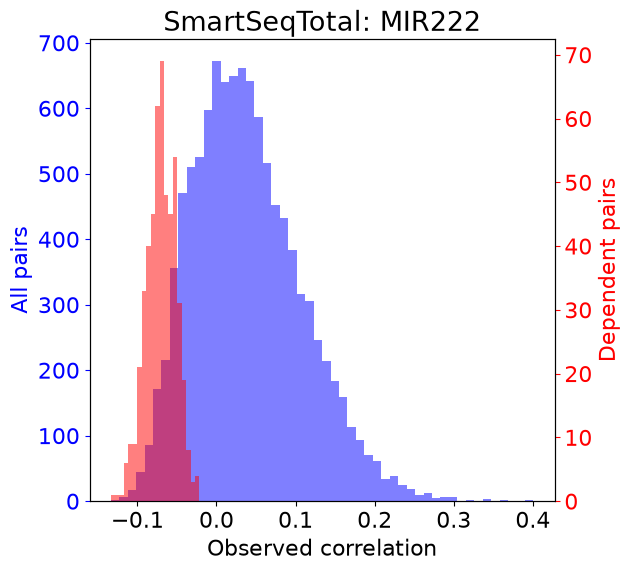

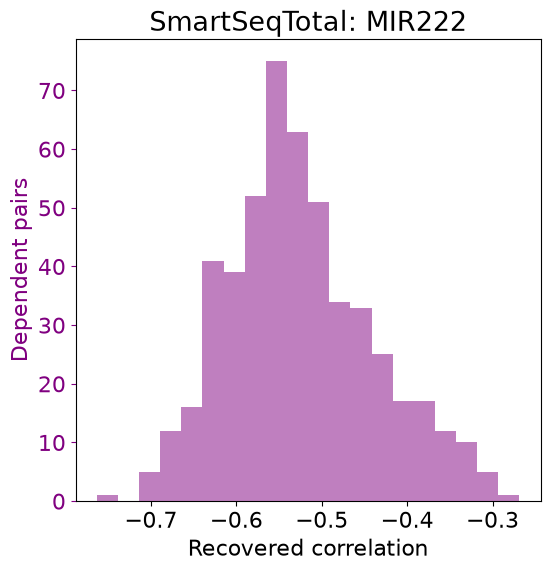

In [54]:
# selection
title = "SmartSeqTotal: MIR222"
miRNA = "MIR222"
MF_ind_chosen = ST_MF_ind_df
MF_int_chosen = ST_MF_int_df
corr_chosen = ST_corr_df

# data
mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
mid = MF_int_chosen[f'{miRNA}_HAR_mid']
OB = corr_chosen[f'{miRNA}_OB']

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))
axs2 = axs.twinx()

axs.hist(OB, bins=50, color="blue", alpha=0.5, density=False, label="All pairs")
axs.set_ylabel("All pairs", color="blue")
axs.tick_params('y', colors="blue")
#axs.legend()

axs2.hist(OB[mask], bins=20, color="red", alpha=0.5, density=False, label="Dependent pairs")
axs2.set_ylabel("Dependent pairs", color="red")
axs2.tick_params('y', colors="red")
#axs2.legend()

axs.set_xlabel("Observed correlation")
#axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid[mask], bins=20, color="purple", alpha=0.5, density=False, label="Dependent pairs")
axs.set_ylabel("Dependent pairs", color="purple")
axs.tick_params('y', colors="purple")
#axs.legend()

axs.set_xlabel("Recovered correlation")
#axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

### Shared xlim

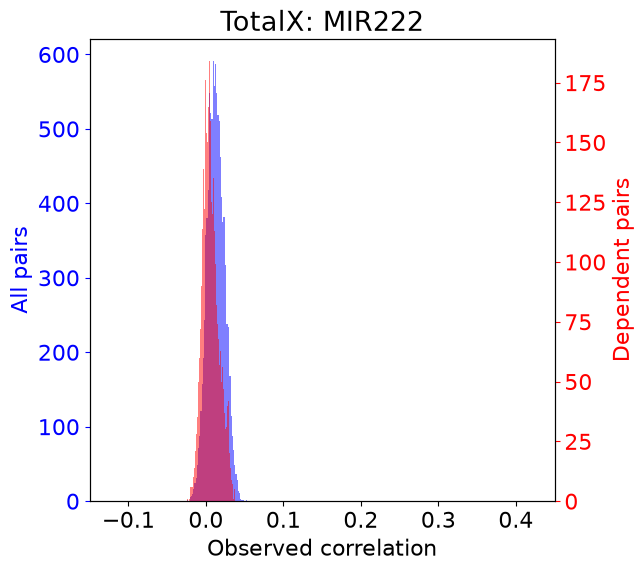

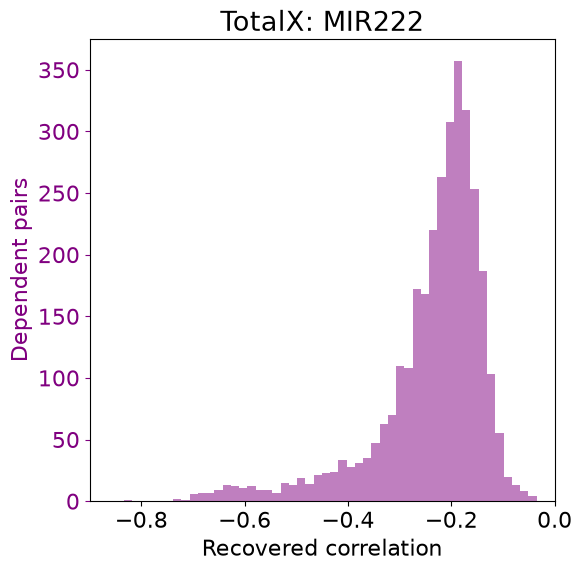

In [61]:
# selection
title = "TotalX: MIR222"
miRNA = "MIR222"
MF_ind_chosen = TX_MIR222_MF_ind_df
MF_int_chosen = TX_MIR222_MF_int_df
corr_chosen = TX_MIR222_corr_df

# data
mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
mid = MF_int_chosen[f'{miRNA}_HAR_mid']
OB = corr_chosen[f'{miRNA}_OB']

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))
axs2 = axs.twinx()

axs.hist(OB, bins=50, color="blue", alpha=0.5, density=False, label="All pairs")
axs.set_ylabel("All pairs", color="blue")
axs.tick_params('y', colors="blue")
#axs.legend()

axs2.hist(OB[mask], bins=50, color="red", alpha=0.5, density=False, label="Dependent pairs")
axs2.set_ylabel("Dependent pairs", color="red")
axs2.tick_params('y', colors="red")
#axs2.legend()

axs.set_xlabel("Observed correlation")
axs.set_xlim(-0.15, 0.45)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid[mask], bins=50, color="purple", alpha=0.5, density=False, label="Dependent pairs")
axs.set_ylabel("Dependent pairs", color="purple")
axs.tick_params('y', colors="purple")
#axs.legend()

axs.set_xlabel("Recovered correlation")
axs.set_xlim(-0.9, 0.0)

axs.set_title(title)

plt.show()

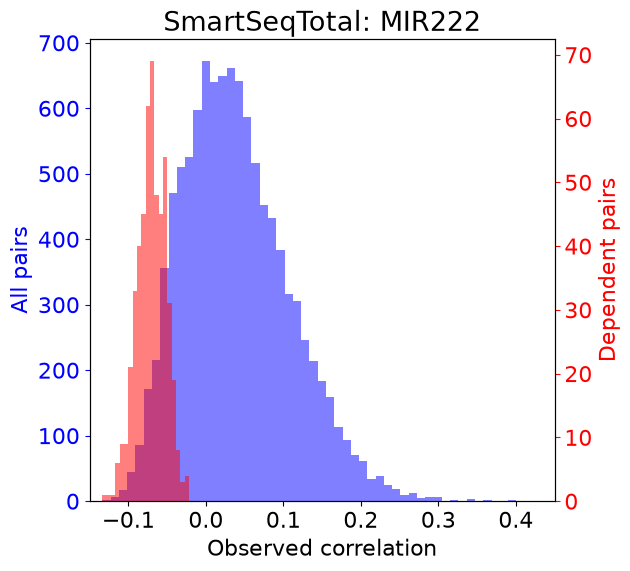

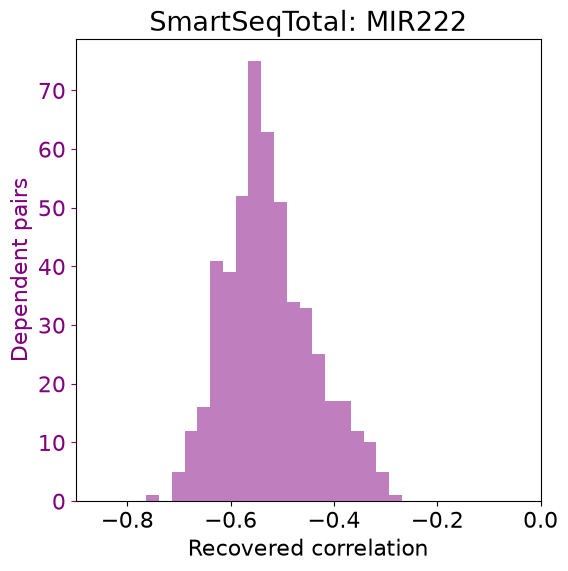

In [62]:
# selection
title = "SmartSeqTotal: MIR222"
miRNA = "MIR222"
MF_ind_chosen = ST_MF_ind_df
MF_int_chosen = ST_MF_int_df
corr_chosen = ST_corr_df

# data
mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
mid = MF_int_chosen[f'{miRNA}_HAR_mid']
OB = corr_chosen[f'{miRNA}_OB']

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))
axs2 = axs.twinx()

axs.hist(OB, bins=50, color="blue", alpha=0.5, density=False, label="All pairs")
axs.set_ylabel("All pairs", color="blue")
axs.tick_params('y', colors="blue")
#axs.legend()

axs2.hist(OB[mask], bins=20, color="red", alpha=0.5, density=False, label="Dependent pairs")
axs2.set_ylabel("Dependent pairs", color="red")
axs2.tick_params('y', colors="red")
#axs2.legend()

axs.set_xlabel("Observed correlation")
axs.set_xlim(-0.15, 0.45)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid[mask], bins=20, color="purple", alpha=0.5, density=False, label="Dependent pairs")
axs.set_ylabel("Dependent pairs", color="purple")
axs.tick_params('y', colors="purple")
#axs.legend()

axs.set_xlabel("Recovered correlation")
axs.set_xlim(-0.9, 0.0)

axs.set_title(title)

plt.show()

## All miRNA

### Default

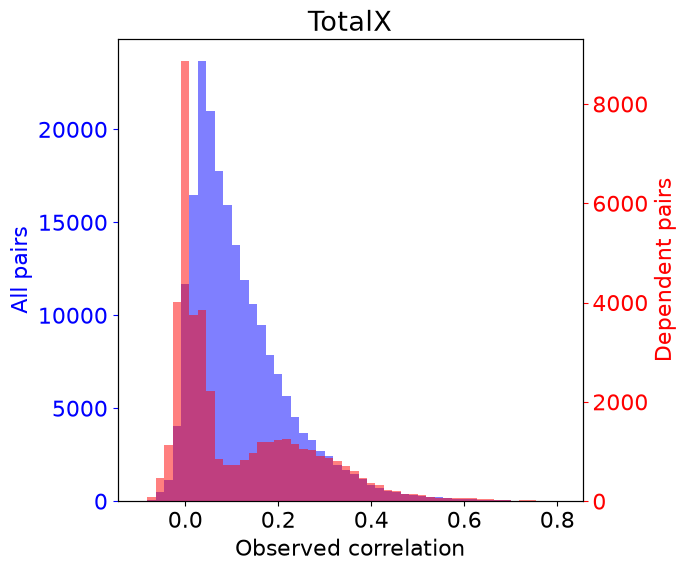

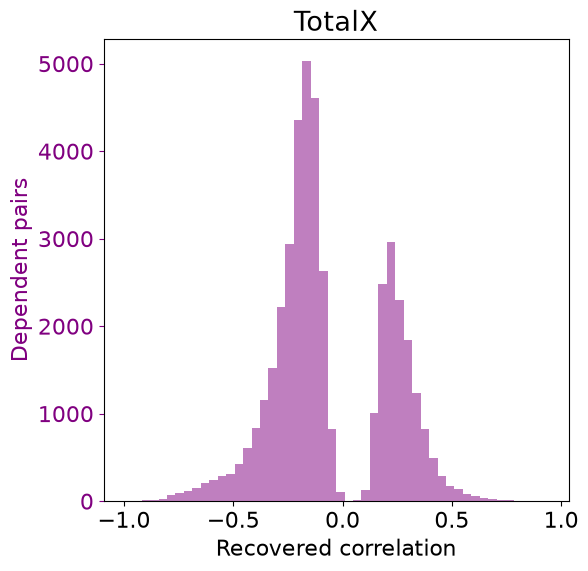

In [64]:
# selection
title = "TotalX"
miRNA_names_chosen = TX_miRNA_names
MF_ind_chosen = TX_MF_ind_df
MF_int_chosen = TX_MF_int_df
corr_chosen = TX_corr_df

# data
OB_all = []
OB_mask_all = []
mid_mask_all = []
for miRNA in miRNA_names_chosen:
    mask = (MF_ind_chosen[f'{miRNA}_All_status'] == "INFEASIBLE").values.squeeze()
    mid = MF_int_chosen[f'{miRNA}_All_HAR_mid']
    OB = corr_chosen[f'{miRNA}_All_OB']
    OB_all += OB.tolist()
    OB_mask_all += OB[mask].tolist()
    mid_mask_all += mid[mask].tolist()

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))
axs2 = axs.twinx()

axs.hist(OB_all, bins=50, color="blue", alpha=0.5, density=False, label="All pairs")
axs.set_ylabel("All pairs", color="blue")
axs.tick_params('y', colors="blue")
#axs.legend()

axs2.hist(OB_mask_all, bins=50, color="red", alpha=0.5, density=False, label="Dependent pairs")
axs2.set_ylabel("Dependent pairs", color="red")
axs2.tick_params('y', colors="red")
#axs2.legend()

axs.set_xlabel("Observed correlation")
#axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid_mask_all, bins=50, color="purple", alpha=0.5, density=False, label="Dependent pairs")
axs.set_ylabel("Dependent pairs", color="purple")
axs.tick_params('y', colors="purple")
#axs.legend()

axs.set_xlabel("Recovered correlation")
#axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

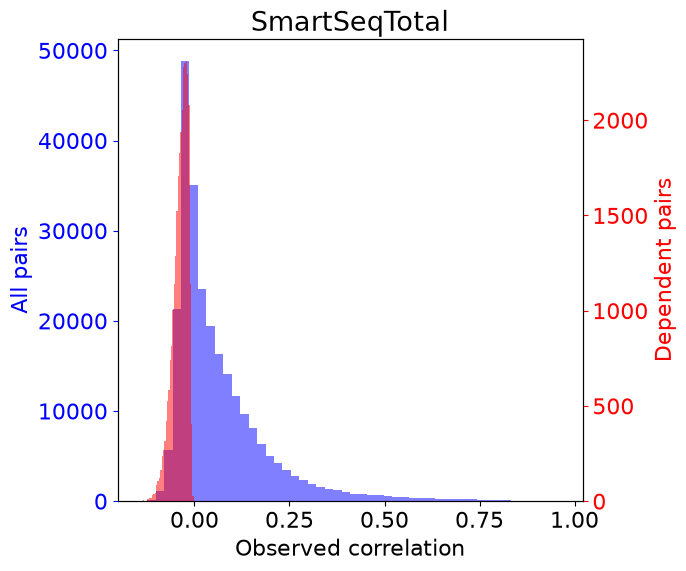

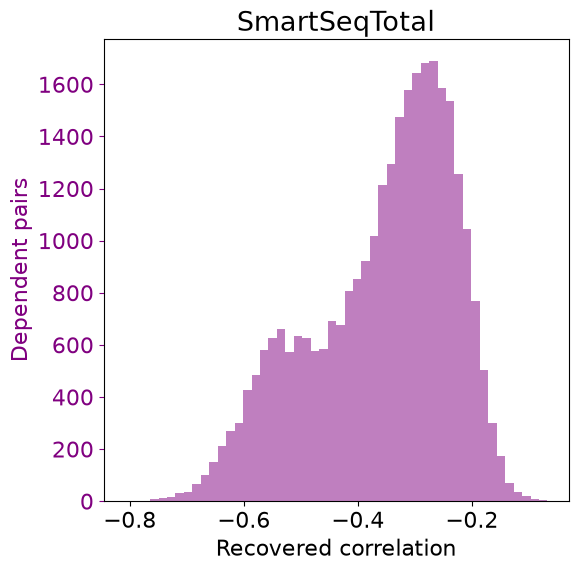

In [66]:
# selection
title = "SmartSeqTotal"
miRNA_names_chosen = ST_miRNA_names
MF_ind_chosen = ST_MF_ind_df
MF_int_chosen = ST_MF_int_df
corr_chosen = ST_corr_df

# data
OB_all = []
OB_mask_all = []
mid_mask_all = []
for miRNA in miRNA_names_chosen:
    mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
    mid = MF_int_chosen[f'{miRNA}_HAR_mid']
    OB = corr_chosen[f'{miRNA}_OB']
    OB_all += OB.tolist()
    OB_mask_all += OB[mask].tolist()
    mid_mask_all += mid[mask].tolist()

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))
axs2 = axs.twinx()

axs.hist(OB_all, bins=50, color="blue", alpha=0.5, density=False, label="All pairs")
axs.set_ylabel("All pairs", color="blue")
axs.tick_params('y', colors="blue")
#axs.legend()

axs2.hist(OB_mask_all, bins=50, color="red", alpha=0.5, density=False, label="Dependent pairs")
axs2.set_ylabel("Dependent pairs", color="red")
axs2.tick_params('y', colors="red")
#axs2.legend()

axs.set_xlabel("Observed correlation")
#axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid_mask_all, bins=50, color="purple", alpha=0.5, density=False, label="Dependent pairs")
axs.set_ylabel("Dependent pairs", color="purple")
axs.tick_params('y', colors="purple")
#axs.legend()

axs.set_xlabel("Recovered correlation")
#axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

### Shared xlim

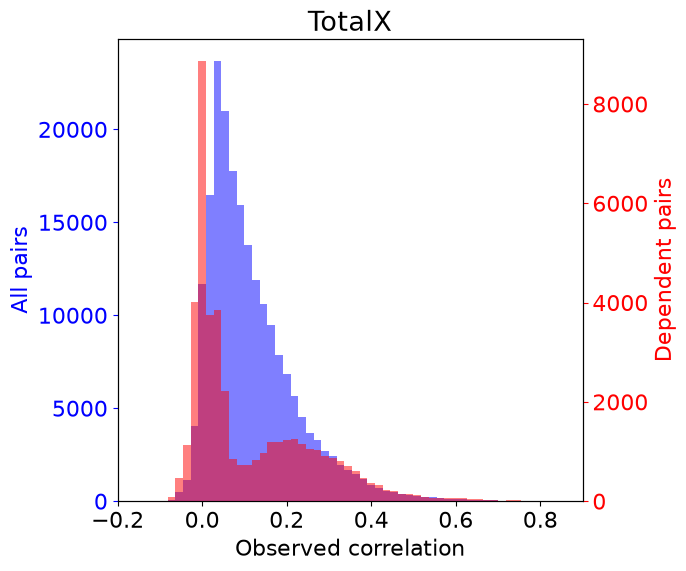

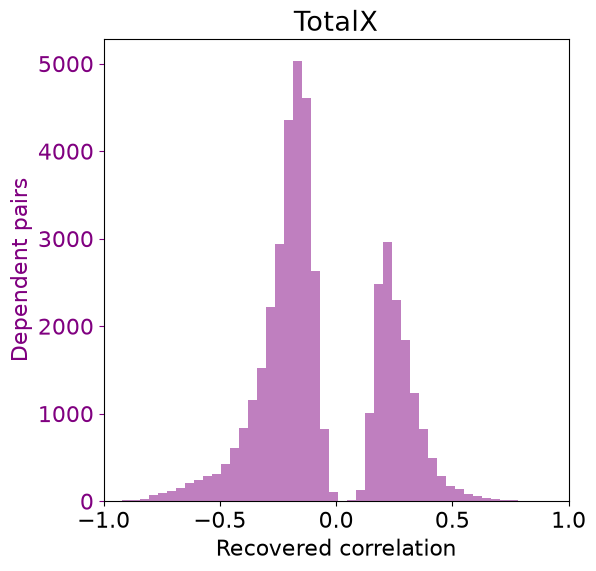

In [67]:
# selection
title = "TotalX"
miRNA_names_chosen = TX_miRNA_names
MF_ind_chosen = TX_MF_ind_df
MF_int_chosen = TX_MF_int_df
corr_chosen = TX_corr_df

# data
OB_all = []
OB_mask_all = []
mid_mask_all = []
for miRNA in miRNA_names_chosen:
    mask = (MF_ind_chosen[f'{miRNA}_All_status'] == "INFEASIBLE").values.squeeze()
    mid = MF_int_chosen[f'{miRNA}_All_HAR_mid']
    OB = corr_chosen[f'{miRNA}_All_OB']
    OB_all += OB.tolist()
    OB_mask_all += OB[mask].tolist()
    mid_mask_all += mid[mask].tolist()

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))
axs2 = axs.twinx()

axs.hist(OB_all, bins=50, color="blue", alpha=0.5, density=False, label="All pairs")
axs.set_ylabel("All pairs", color="blue")
axs.tick_params('y', colors="blue")
#axs.legend()

axs2.hist(OB_mask_all, bins=50, color="red", alpha=0.5, density=False, label="Dependent pairs")
axs2.set_ylabel("Dependent pairs", color="red")
axs2.tick_params('y', colors="red")
#axs2.legend()

axs.set_xlabel("Observed correlation")
axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid_mask_all, bins=50, color="purple", alpha=0.5, density=False, label="Dependent pairs")
axs.set_ylabel("Dependent pairs", color="purple")
axs.tick_params('y', colors="purple")
#axs.legend()

axs.set_xlabel("Recovered correlation")
axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

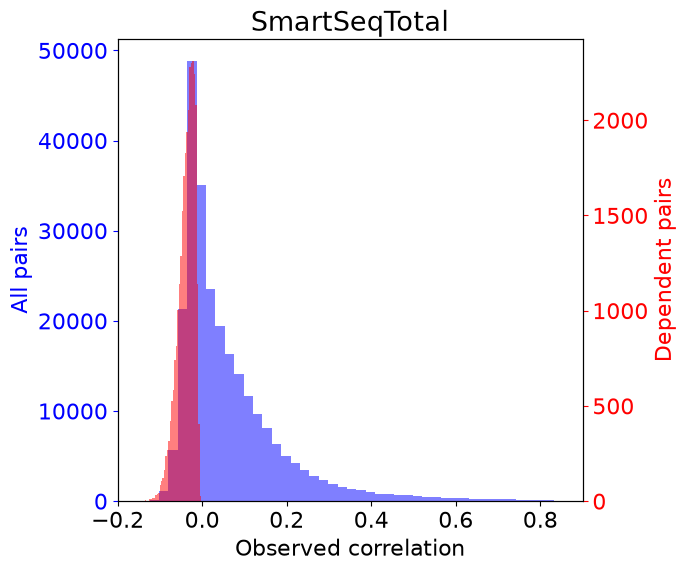

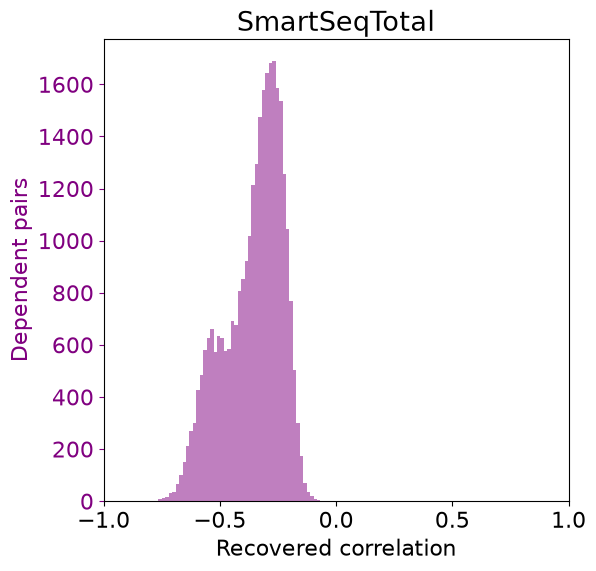

In [68]:
# selection
title = "SmartSeqTotal"
miRNA_names_chosen = ST_miRNA_names
MF_ind_chosen = ST_MF_ind_df
MF_int_chosen = ST_MF_int_df
corr_chosen = ST_corr_df

# data
OB_all = []
OB_mask_all = []
mid_mask_all = []
for miRNA in miRNA_names_chosen:
    mask = (MF_ind_chosen[f'{miRNA}_status'] == "INFEASIBLE").values.squeeze()
    mid = MF_int_chosen[f'{miRNA}_HAR_mid']
    OB = corr_chosen[f'{miRNA}_OB']
    OB_all += OB.tolist()
    OB_mask_all += OB[mask].tolist()
    mid_mask_all += mid[mask].tolist()

# observed correlation
fig, axs = plt.subplots(figsize=(6, 6))
axs2 = axs.twinx()

axs.hist(OB_all, bins=50, color="blue", alpha=0.5, density=False, label="All pairs")
axs.set_ylabel("All pairs", color="blue")
axs.tick_params('y', colors="blue")
#axs.legend()

axs2.hist(OB_mask_all, bins=50, color="red", alpha=0.5, density=False, label="Dependent pairs")
axs2.set_ylabel("Dependent pairs", color="red")
axs2.tick_params('y', colors="red")
#axs2.legend()

axs.set_xlabel("Observed correlation")
axs.set_xlim(-0.2, 0.9)

axs.set_title(title)

plt.show()

# recovered correlation
fig, axs = plt.subplots(figsize=(6, 6))

axs.hist(mid_mask_all, bins=50, color="purple", alpha=0.5, density=False, label="Dependent pairs")
axs.set_ylabel("Dependent pairs", color="purple")
axs.tick_params('y', colors="purple")
#axs.legend()

axs.set_xlabel("Recovered correlation")
axs.set_xlim(-1, 1)

axs.set_title(title)

plt.show()

# Phase Dependence Table

In [69]:
# select all categories
miRNA_names = TX_miRNA_names
phase_names = phases

# table of miRNA x phases
ind_table = pd.DataFrame(
    index=["Total"] + miRNA_names,
    columns=phase_names,
    dtype=float
)

# fill
for phase in phase_names:
    for miRNA in miRNA_names:
        ind_table.loc[miRNA, phase] = (TX_MF_ind_df[f'{miRNA}_{phase}_status'] == "INFEASIBLE").mean() * 100
    ind_table.loc['Total', phase] = ind_table.loc[miRNA_names, phase].mean()

# display
ind_table.style.format(precision=2).background_gradient(axis=1, cmap="Blues")

,All,G1,S,G2M
Total,20.87,15.33,8.41,8.46
MIR3917,0.68,34.18,0.87,0.57
MIR5087,2.28,11.84,0.96,1.17
MIR3658,20.30,11.02,4.23,4.46
MIR4426,23.55,13.47,10.94,4.89
MIR4444-1,9.49,5.34,1.04,2.87
MIR1244-1,20.68,12.14,10.07,5.05
MIR3655,9.33,6.06,3.29,2.49
MIR4647,8.00,11.98,1.50,1.66
MIR3654,28.88,8.94,3.84,2.39


# Phase Observed - Recovered Violins

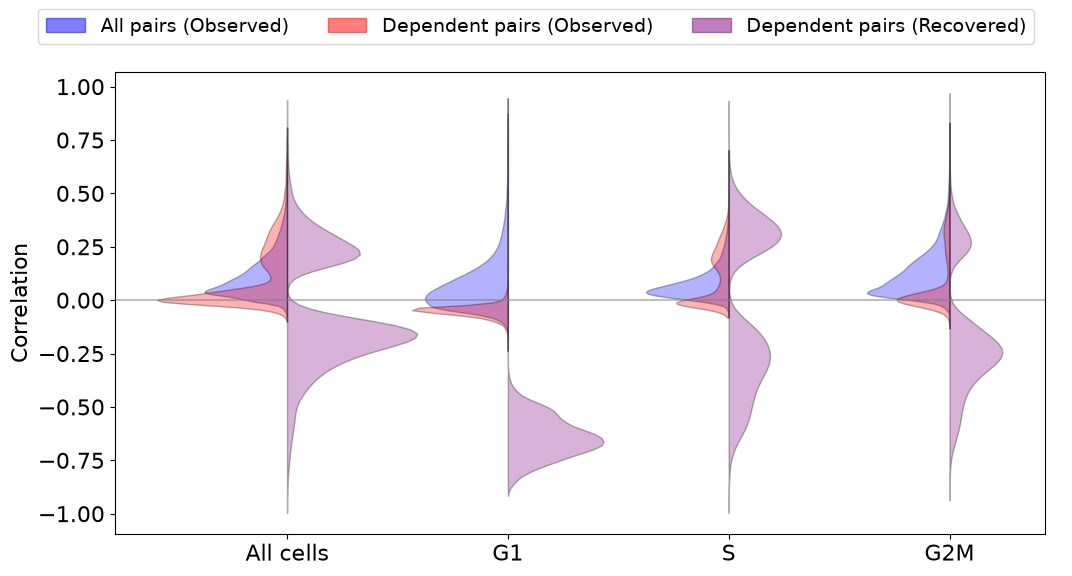

In [104]:
miRNA_names = TX_miRNA_names

all_corr_HR = TX_MF_int_df[[f"{miRNA}_All_HAR_mid" for miRNA in miRNA_names]].values.flatten()
all_mask = ~np.isnan(all_corr_HR)
all_corr_HR = all_corr_HR[all_mask]

G1_corr_HR = TX_MF_int_df[[f"{miRNA}_G1_HAR_mid" for miRNA in miRNA_names]].values.flatten()
G1_mask = ~np.isnan(G1_corr_HR)
G1_corr_HR = G1_corr_HR[G1_mask]

S_corr_HR = TX_MF_int_df[[f"{miRNA}_S_HAR_mid" for miRNA in miRNA_names]].values.flatten()
S_mask = ~np.isnan(S_corr_HR)
S_corr_HR = S_corr_HR[S_mask]

G2M_corr_HR = TX_MF_int_df[[f"{miRNA}_G2M_HAR_mid" for miRNA in miRNA_names]].values.flatten()
G2M_mask = ~np.isnan(G2M_corr_HR)
G2M_corr_HR = G2M_corr_HR[G2M_mask]

all_corr_OB = TX_corr_df[[f"{miRNA}_All_OB" for miRNA in miRNA_names]].values.flatten()
all_corr_OB_int = all_corr_OB[all_mask]

G1_corr_OB = TX_corr_df[[f"{miRNA}_G1_OB" for miRNA in miRNA_names]].values.flatten()
G1_corr_OB_int = G1_corr_OB[G1_mask]

S_corr_OB = TX_corr_df[[f"{miRNA}_S_OB" for miRNA in miRNA_names]].values.flatten()
S_corr_OB_int = S_corr_OB[S_mask]

G2M_corr_OB = TX_corr_df[[f"{miRNA}_G2M_OB" for miRNA in miRNA_names]].values.flatten()
G2M_corr_OB_int = G2M_corr_OB[G2M_mask]

fig, axs = plt.subplots(figsize=(12, 6))
k = 3

# all observed
plot_data_list = [
    all_corr_OB,
    G1_corr_OB,
    S_corr_OB,
    G2M_corr_OB
]
total_size = sum([dt.size for dt in plot_data_list])
for i, plot_data in enumerate(plot_data_list):
    vp = axs.violinplot(
        dataset=plot_data,
        positions=[i],
        showextrema=False,
        side="low",
        widths=k * (plot_data.size / total_size)
    )
    vp['bodies'][0].set_facecolor("blue")
    vp['bodies'][0].set_edgecolor("black")

# interacting observed
plot_data_list = [
    all_corr_OB_int,
    G1_corr_OB_int,
    S_corr_OB_int,
    G2M_corr_OB_int
]
total_size = sum([dt.size for dt in plot_data_list])
for i, plot_data in enumerate(plot_data_list):
    vp = axs.violinplot(
        dataset=plot_data,
        positions=[i],
        showextrema=False,
        side="low",
        widths=k * (plot_data.size / total_size)
    )
    vp['bodies'][0].set_facecolor("red")
    vp['bodies'][0].set_edgecolor("black")

# interacting recovered
plot_data_list = [
    all_corr_HR,
    G1_corr_HR,
    S_corr_HR,
    G2M_corr_HR
]
total_size = sum([dt.size for dt in plot_data_list])
for i, plot_data in enumerate(plot_data_list):
    vp = axs.violinplot(
        dataset=plot_data,
        positions=[i],
        showextrema=False,
        side="high",
        widths=k * (plot_data.size / total_size)
    )
    vp['bodies'][0].set_facecolor("purple")
    vp['bodies'][0].set_edgecolor("black")


#plt.axvspan(0, 0, 0, 0, color="white", label="Observed | Recovered")
plt.axvspan(0, 0, 0, 0, alpha=0.5, color="blue", label="All pairs (Observed)")
plt.axvspan(0, 0, 0, 0, alpha=0.5, color="red", label="Dependent pairs (Observed)")
plt.axvspan(0, 0, 0, 0, alpha=0.5, color="purple", label="Dependent pairs (Recovered)")
fig.legend(fontsize=14, ncols=3, loc="outside upper center")

axs.axhline(0, color="grey", alpha=0.5)
axs.set_xticks([0, 1, 2, 3])
axs.set_xticklabels(["All cells", "G1", "S", "G2M"])
#axs.set_xlabel("Cell Cycle Phase")
axs.set_ylabel("Correlation")
#axs.set_title("microRNA - mRNA Correlation: Cell Cycle Effect")
plt.show()

# Phase Correlation Networks

In [115]:
def construct_network(phase, G1, G2, k, K, d, D, t, plot=False):

    # data
    miRNA_names = TX_miRNA_names
    mRNA_names = TX_mRNA_names
    int_df = TX_MF_int_df

    # select named miRNA & mRNA
    miRNA_names = [miRNA_names[i] for i in G1]
    mRNA_names = [mRNA_names[i] for i in G2]

    corr_df = int_df.loc[mRNA_names, [f'{miRNA}_{phase}_HAR_mid' for miRNA in miRNA_names]]

    # select mRNA with [k, K] interactions
    mask = (k <= corr_df.notna().sum(axis=1)) & (corr_df.notna().sum(axis=1) <= K)
    corr_df = corr_df[mask]

    # select mRNA with [d, D] interactions above threshold t
    mask_thresh = ((t <= corr_df) | (corr_df <= -t)).sum(axis=1)
    mask = (d <= mask_thresh) & (mask_thresh <= D)
    corr_df = corr_df[mask]

    # size
    N_mRNA, N_miRNA = corr_df.shape
    corrs = np.array(corr_df)

    # construct edges
    idxs = np.where(~np.isnan(corrs))
    edges = [(int(j), N_miRNA + int(i)) for i, j in zip(*idxs)]

    # get edge correlations
    corrs = corrs[idxs]

    # total vertices
    vertices = N_miRNA + N_mRNA

    # color, label, size different for miRNA vs mRNA
    vertex_color = ["orange"] * N_miRNA + ["black"] * N_mRNA
    vertex_size = [30] * N_miRNA + [5] * N_mRNA
    vertex_label = miRNA_names + [None] * N_mRNA

    # edge width: constant or can relate to correlation strength
    edge_width = [2 for c in corrs] # int(abs(c) * 10)

    # edge color: red for negative, blue for positive, alpha of strength
    edge_color = [(1, 0, 0, -c) if c < 0 else (0, 0, 1, c) for c in corrs]

    # display size
    print(f"{len(edges)} edges between {vertices} vertices")

    if plot:

        # construct graph
        g = ig.Graph(vertices, edges)

        fig, axs = plt.subplots(figsize=(16, 16))
        
        ig.plot(
            g,
            target=axs,
            #layout="large", # node layout algorithm
            vertex_size=vertex_size,
            vertex_color=vertex_color,
            vertex_frame_width=1,
            vertex_label=vertex_label,
            vertex_label_size=10,
            edge_width=edge_width,
            edge_color=edge_color
        )

        if phase == "All":
            title = "All cells"
        else:
            title = phase
        axs.set_title(title, fontsize=50)

        plt.show()

166 edges between 87 vertices


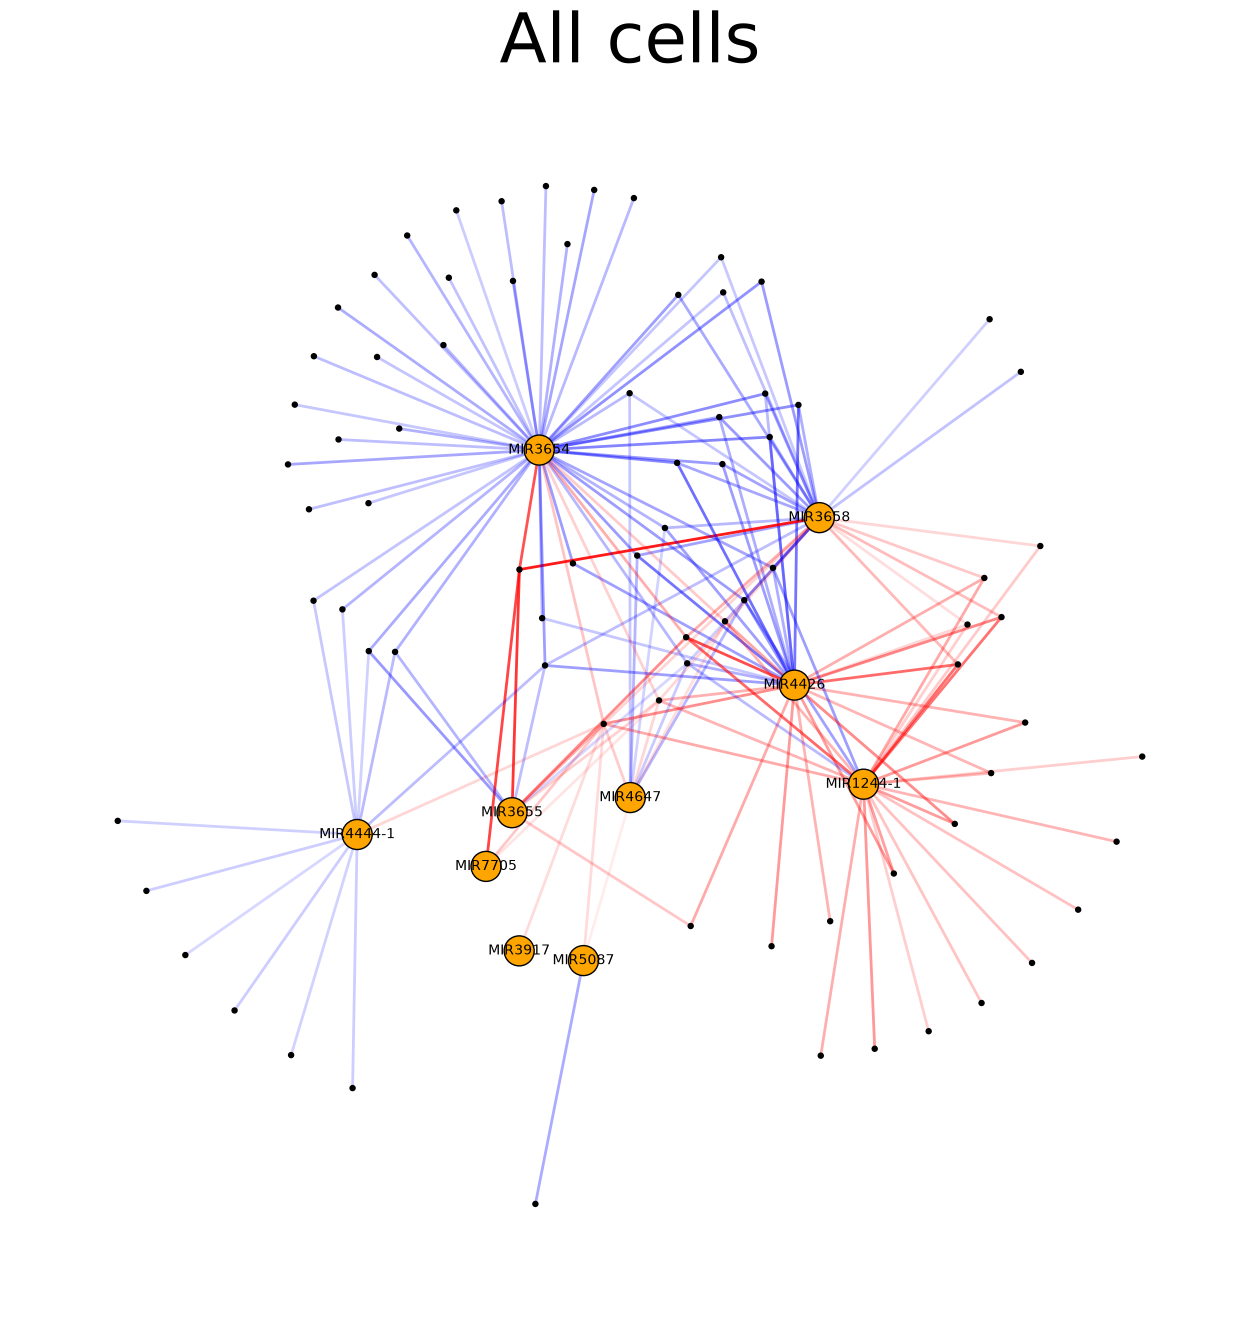

173 edges between 110 vertices


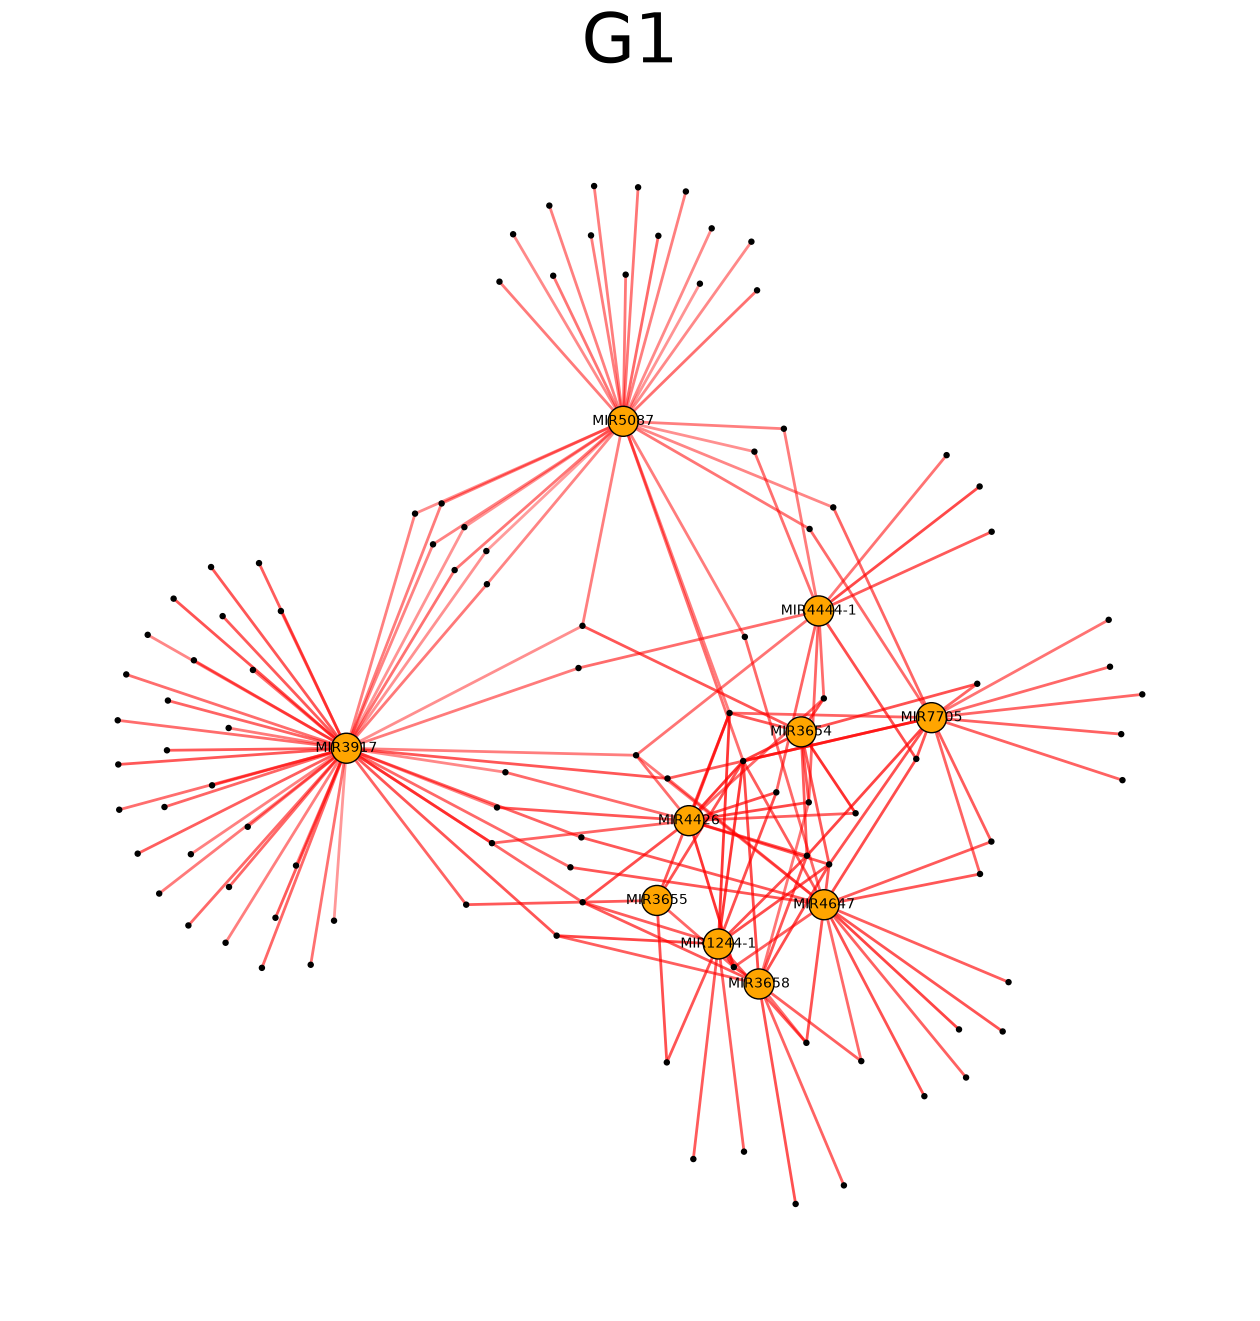

44 edges between 33 vertices


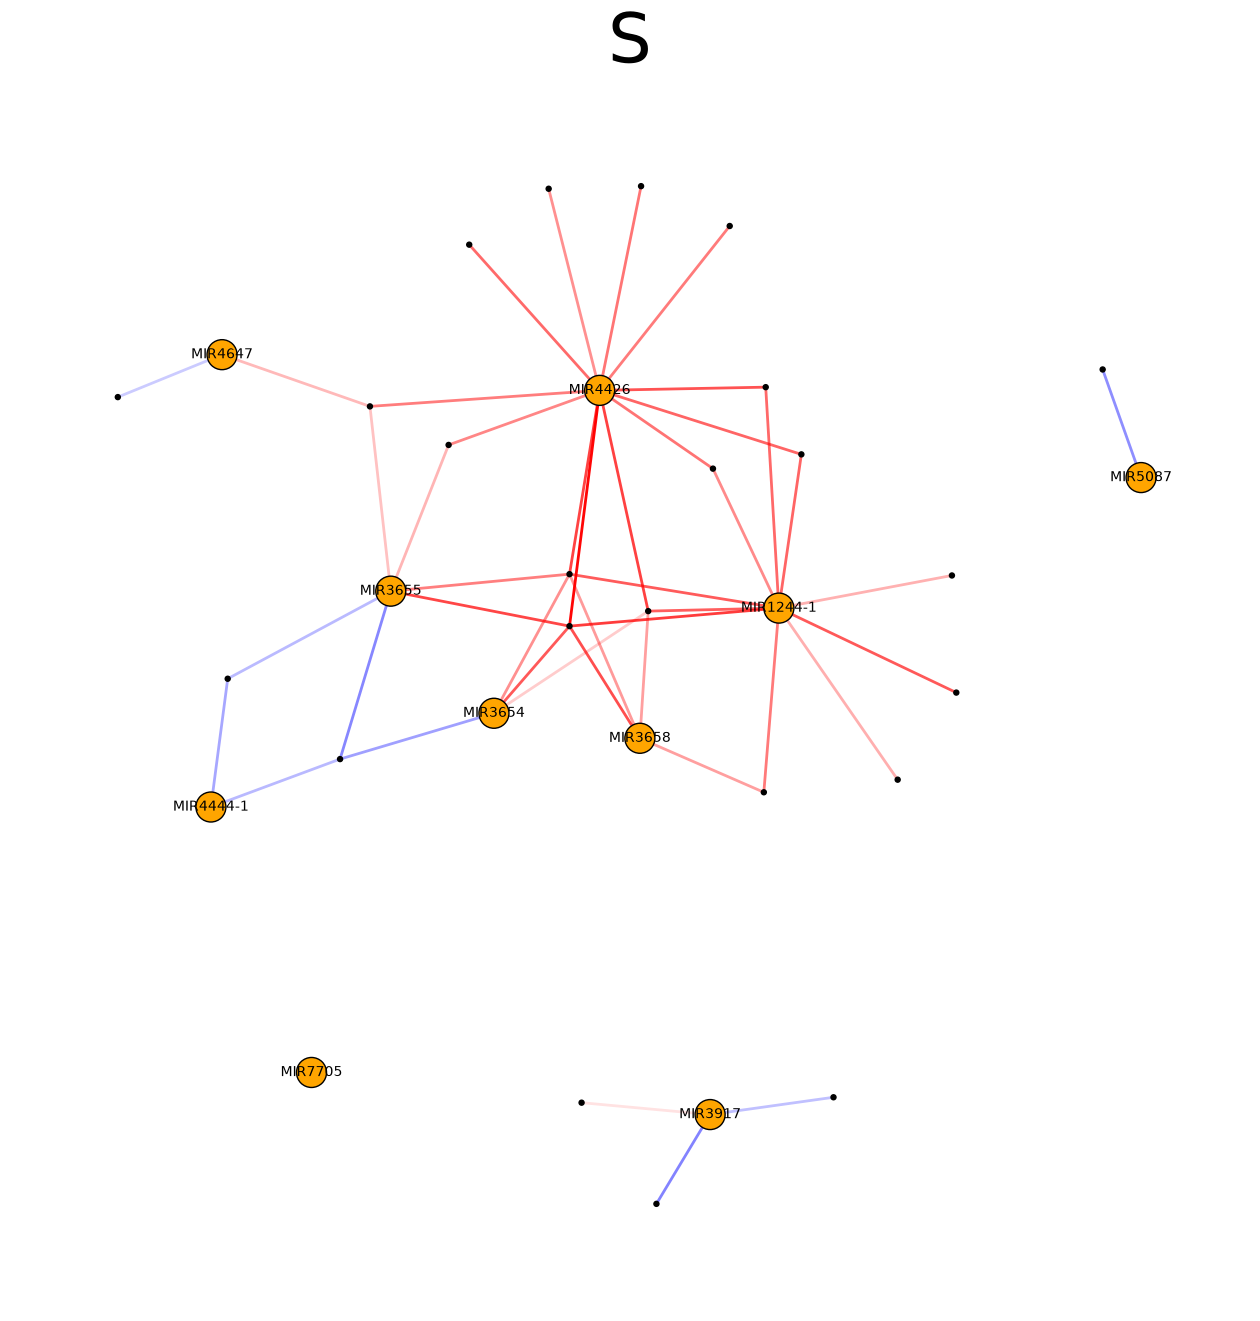

26 edges between 22 vertices


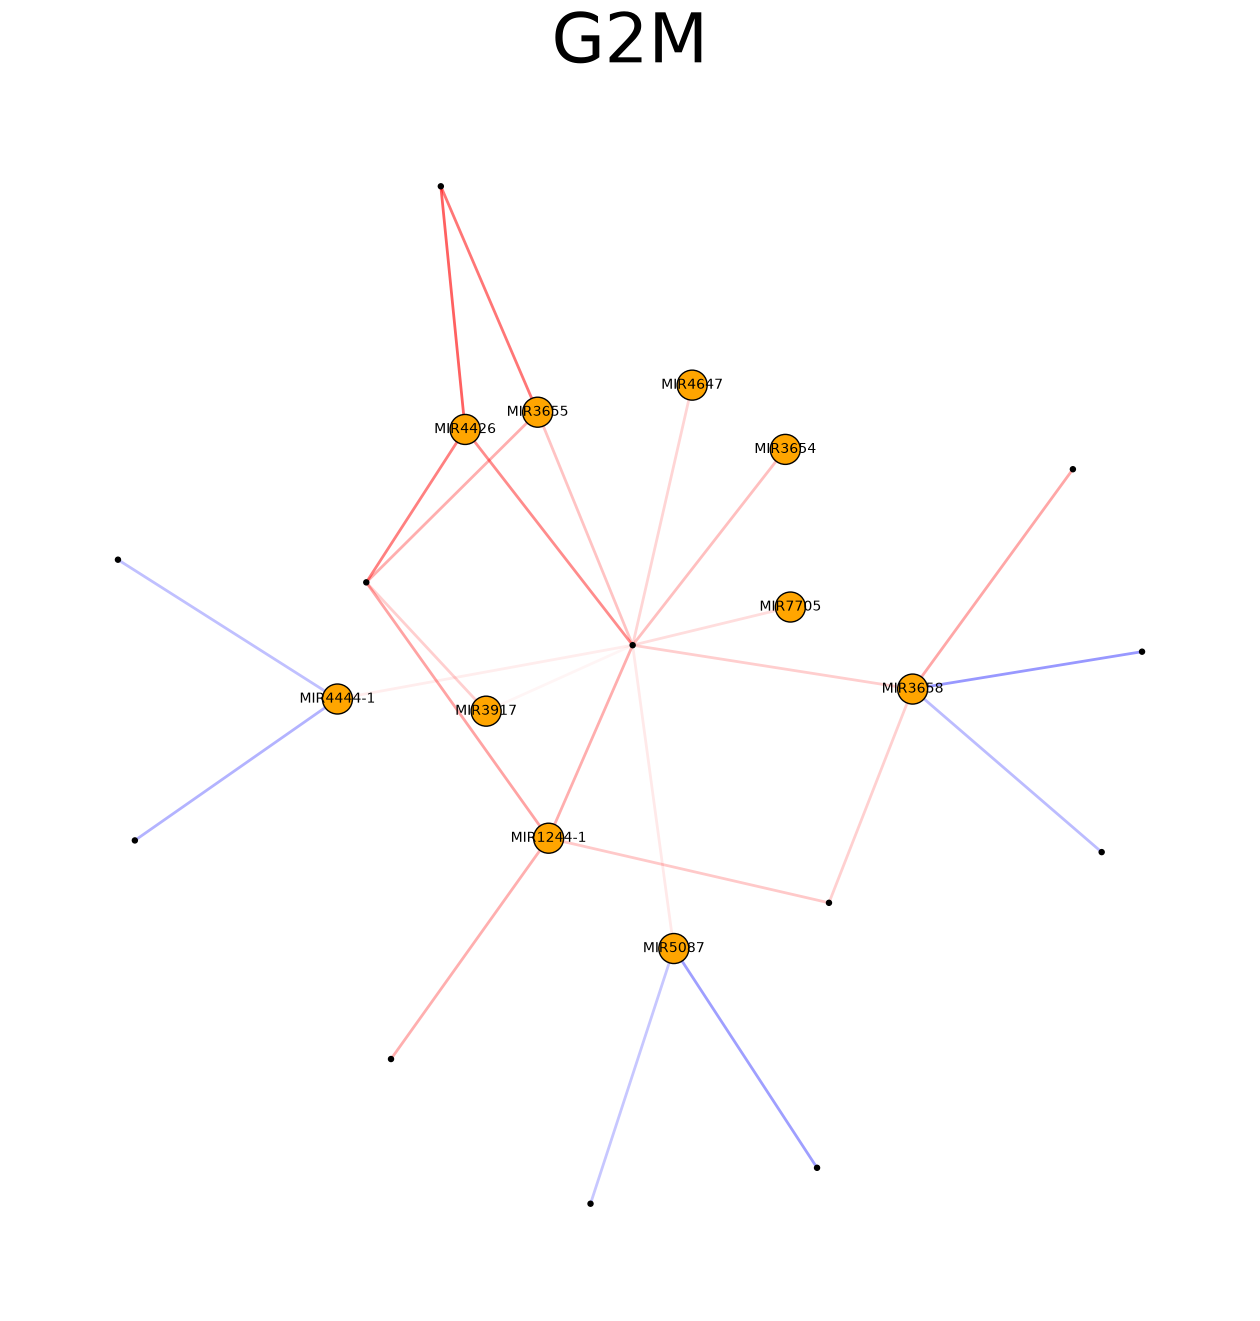

In [116]:
# settings
G1 = np.array([x for x in range(0, 10)])
G2 = np.arange(200)
k, K = 1, 20
d, D = 1, 20
t = 0.0

construct_network("All", G1, G2, k, K, d, D, t, plot=True)
construct_network("G1", G1, G2, k, K, d, D, t, plot=True)
construct_network("S", G1, G2, k, K, d, D, t, plot=True)
construct_network("G2M", G1, G2, k, K, d, D, t, plot=True)

# Simulated data

- spurious correlation
- recovered correlation fit

In [117]:
rng = np.random.default_rng(0)

In [118]:
# run size
N = 200
n = 2000

# parameters
mu1 = 10
mu2 = 10
s1 = 5
s2 = 5

mui = 10
si = 5

m = 0.5

counts_OG = np.zeros((N, n, 2), dtype=np.int64)
counts_OB = np.zeros((N, n, 2), dtype=np.int64)

if m == 0:
    beta = np.ones(n)
else:
    b = (1 / m) - 1
    beta = rng.beta(1, b, size=n)

i = 0
for rho in np.linspace(-1, 0.75, N):

    s1 = rng.normal(si, 0.5)
    s2 = rng.normal(si, 0.5)
    mu1 = rng.normal(mui, 2)
    mu2 = rng.normal(mui, 2)

    Sigma = np.array([
        [s1**2, rho*s1*s2],
        [rho*s1*s2, s2**2]
    ])
    mu = np.array([mu1, mu2])

    x_OG = rng.multivariate_normal(mu, Sigma, size=n)
    x_OG = x_OG.astype(np.int64)
    x_OG[x_OG < 0] = 0

    x_OB = rng.binomial(x_OG, beta[:, None]).astype(np.int64)

    counts_OG[i, :, :] = x_OG
    counts_OB[i, :, :] = x_OB

    i += 1

In [119]:
corr_OG = []
corr_OB = []

for i in range(N):

    rho_OG = np.corrcoef(counts_OG[i, :, :].T)[0, 1]
    rho_OB = np.corrcoef(counts_OB[i, :, :].T)[0, 1]

    corr_OG.append(rho_OG)
    corr_OB.append(rho_OB)

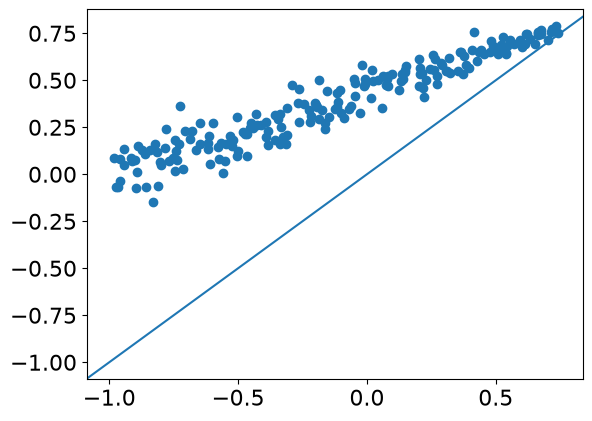

In [120]:
plt.scatter(corr_OG, corr_OB)
plt.axline([-1, -1], [0.75, 0.75])

In [121]:
gene_queries = [
    [[int(i)], [int(i)]] for i in range(N)
]

SDP_data = SDP_miRNA.dataset.Dataset()
SDP_data.construct_dataset_array(
    counts_OB[:, :, 0].T,
    counts_OB[:, :, 1].T,
    beta,
    gene_queries
)
SDP_data.bootstrap(d=3)

100%|██████████| 2/2 [00:00<00:00,  6.46it/s]


In [122]:
MF_int = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data, d=3)
MF_int.analyse_dataset()

_, HAR_intervals = MF_int.compute_dataset_correlation()
HAR_mid = (HAR_intervals[:, 0] + HAR_intervals[:, 1]) / 2

100%|██████████| 200/200 [00:01<00:00, 111.97it/s]


In [123]:
# coverage
mask = (HAR_intervals[:, 0] <= np.array(corr_OG)) & (np.array(corr_OG) <= HAR_intervals[:, 1])
coverage = float(np.mean(mask))

# mse
mse = float(np.mean((np.array(corr_OG) - HAR_mid)**2))

coverage, mse

(1.0, 0.014728244791497773)

## Plots

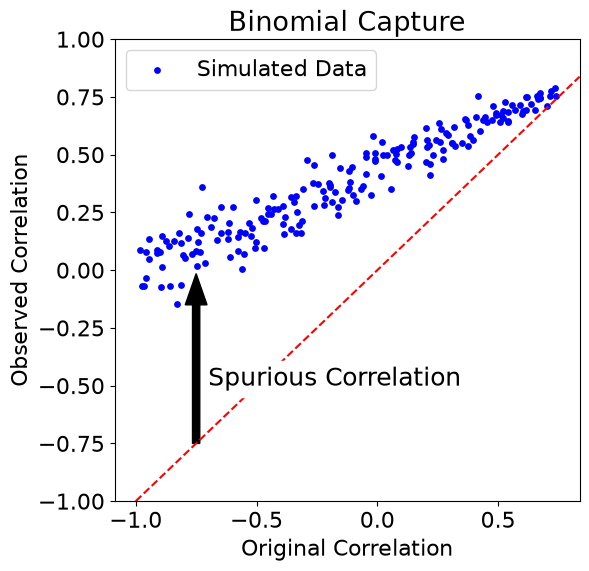

In [170]:
fig, axs = plt.subplots(figsize=(6, 6))
axs.scatter(corr_OG, corr_OB, color="blue", s=15, label="Simulated Data")
axs.axline([-1, -1], [0.75, 0.75], color="red", linestyle="--")
axs.set_xlabel("Original Correlation")
axs.set_ylabel("Observed Correlation")
axs.set_title("Binomial Capture")
axs.legend()
axs.set_ylim(-1, 1)
axs.arrow(-0.75, -0.75, 0, 0.6, width=0.03, color="black", overhang=0.0)
axs.text(-0.7, -0.5, "Spurious Correlation", fontsize=18, backgroundcolor="white")
plt.show()

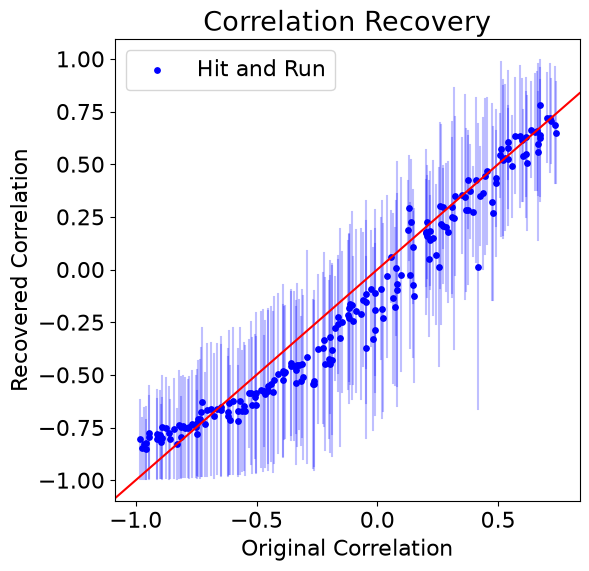

In [165]:
fig, axs = plt.subplots(figsize=(6, 6))
for i in range(N):
    axs.plot([corr_OG[i]]*2, HAR_intervals[i, :], color="blue", alpha=0.25)
axs.scatter(corr_OG, HAR_mid, color="blue", s=15, label="Hit and Run")
axs.axline([-1, -1], [0.75, 0.75], color="red", linestyle="-")
#axs.plot([], [], color="white", label=f"Coverage {round(100 * coverage, 2)}%")
#axs.plot([], [], color="white", label=f"MSE {round(mse, 5)}")
axs.set_xlabel("Original Correlation")
axs.set_ylabel("Recovered Correlation")
axs.set_title("Correlation Recovery")
axs.legend()
plt.show()

## Sample size tests

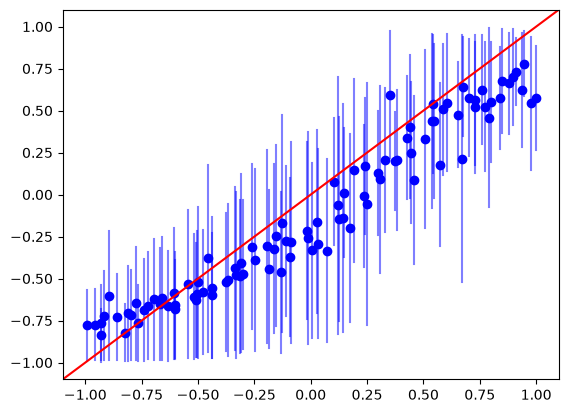

In [116]:
# n = 1,000 cells
for i in range(N):
    plt.plot([corr_OG[i]]*2, HAR_intervals[i, :], color="blue", alpha=0.5)
plt.scatter(corr_OG, HAR_mid, color="blue")
plt.axline([-1, -1], [1, 1], color="red")

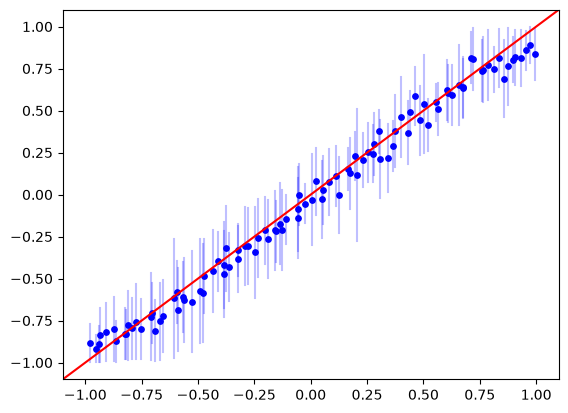

In [125]:
# n = 5,000 cells
for i in range(N):
    plt.plot([corr_OG[i]]*2, HAR_intervals[i, :], color="blue", alpha=0.25)
plt.scatter(corr_OG, HAR_mid, color="blue", s=15)
plt.axline([-1, -1], [1, 1], color="red")

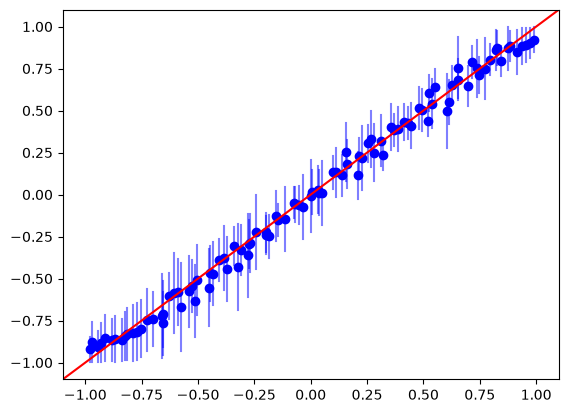

In [ ]:
# n = 10,000 cells
for i in range(N):
    plt.plot([corr_OG[i]]*2, HAR_intervals[i, :], color="blue", alpha=0.5)
plt.scatter(corr_OG, HAR_mid, color="blue")
plt.axline([-1, -1], [1, 1], color="red")

# Future Work Plots

In [200]:
from SDP_miRNA.optimization_utils import compute_feasible_correlation

In [225]:
# load pcRNA
adata_pcRNA = ad.read_h5ad("../TotalX/HEK293T-Cell-Cycle/TotalX_HEK293T_CC_pcRNA.h5ad")

# load miRNA
adata_miRNA = ad.read_h5ad("../TotalX/HEK293T-Cell-Cycle/TotalX_HEK293T_CC_miRNA.h5ad")

# load capture
beta = np.loadtxt("../TotalX/HEK293T/TotalX_HEK293T_capture.txt")
beta_G1 = np.loadtxt("../TotalX/HEK293T-Cell-Cycle/TotalX_HEK293T_G1_capture.txt")
beta_S = np.loadtxt("../TotalX/HEK293T-Cell-Cycle/TotalX_HEK293T_S_capture.txt")
beta_G2M = np.loadtxt("../TotalX/HEK293T-Cell-Cycle/TotalX_HEK293T_G2M_capture.txt")

# max observed count per miRNA
max_count = adata_miRNA.X.max(axis=0).toarray()

# select
count_mask = (max_count >= 3).squeeze()
miRNA_idxs = np.arange(len(count_mask))[count_mask]

# subset miRNA
adata_miRNA = adata_miRNA[:, miRNA_idxs]

# display
print(f"{sum(count_mask)} / {len(count_mask)} miRNA retained")

20 / 41 miRNA retained


In [226]:
adata_miRNA.var['GeneName']

41473            MIR3917
41667            MIR5087
41729            MIR3658
41761            MIR4426
42082          MIR4444-1
42175          MIR1244-1
42850            MIR3655
42989            MIR4647
43286            MIR3654
43453            MIR7705
43803    ENSG00000221184
44278            MIR3652
44515            MIR4709
44883            MIR7706
44936            MIR3178
45178             MIR632
45373            MIR4741
45464            MIR1181
45659            MIR663A
45893            MIR6821
Name: GeneName, dtype: category
Categories (20, str): ['ENSG00000221184', 'MIR632', 'MIR663A', 'MIR1181', ..., 'MIR5087', 'MIR6821', 'MIR7705', 'MIR7706']

## Selection

In [299]:
# settings
miRNA_select = ["MIR3917", "MIR5087", "MIR3658"]
phase_select = "G1"
beta_select = beta_G1
K = 2
M = len(miRNA_select)
T = 10
S = M + T
tau = -0.5

# select results
mid = TX_MF_int_df[[f'{miRNA}_{phase_select}_HAR_mid' for miRNA in miRNA_select]]

# get negatively correlated interacting pcRNA
pcRNA_select = mid[(mid < tau).sum(axis=1) >= K].index.tolist()
pcRNA_select = rng.choice(pcRNA_select, size=T, replace=False)
pcRNA_select

array(['GRK2', 'PLLP', 'RIPOR2', 'AUH', 'ZNF440', 'STAU2', 'CREBRF',
       'NLRX1', 'CDC14A', 'LRRC69'], dtype='<U9')

## Heatmap (pairwise)

In [ ]:
# select data
if phase_select == "All":
    adata_select = ad.concat(
        [
            adata_miRNA[:, adata_miRNA.var['GeneName'].isin(miRNA_select)],
            adata_pcRNA[:, adata_pcRNA.var['GeneName'].isin(pcRNA_select)]
        ],
        axis=1
    )
else:
    adata_select = ad.concat(
            [
                adata_miRNA[adata_miRNA.obs['phase'] == phase_select, adata_miRNA.var['GeneName'].isin(miRNA_select)],
                adata_pcRNA[adata_miRNA.obs['phase'] == phase_select, adata_pcRNA.var['GeneName'].isin(pcRNA_select)]
            ],
            axis=1
        )

# settings
d = 3

# compute correlations between all pairs of M genes: no repeats
Is, Js = np.triu_indices(S, k=1)
gene_queries = [
    [[int(i)], [int(j)]] for i, j in zip(Is, Js)
]

# construct datasets
SDP_data = SDP_miRNA.dataset.Dataset()
SDP_data.construct_dataset_adata(
    adata_select,
    adata_select,
    beta_select,
    gene_queries
)

# bootstrap
SDP_data.bootstrap(d=d)

# model free independence test
MF_ind = SDP_miRNA.optimization.ModelFreeOptimization(SDP_data, d=d)
MF_ind.analyse_dataset()

# model free interacting H&R: should really subset queries to just interacting pairs, but small enough
MF_int = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data, d=d)
MF_int.analyse_dataset()

# H&R correlations
HAR_points, HAR_intervals = MF_int.compute_dataset_correlation()

# H&R midpoints
HAR_mid = (HAR_intervals[:, 0] + HAR_intervals[:, 1]) / 2

# correlation
OB, AL = SDP_miRNA.correlation.compute_correlations(SDP_data)

100%|██████████| 1/1 [00:00<00:00, 12.41it/s]


In [317]:
# construct matrices
corr_matrix_mid = np.zeros((S, S))
corr_matrix_min = np.zeros((S, S))
corr_matrix_max = np.zeros((S, S))
for i, query in enumerate(SDP_data.gene_queries):
    if MF_ind.result_dict[i]['status'] == "INFEASIBLE":
        corr_matrix_mid[query[0][0], query[1][0]] = HAR_mid[i]
        corr_matrix_min[query[0][0], query[1][0]] = HAR_intervals[i, 0]
        corr_matrix_max[query[0][0], query[1][0]] = HAR_intervals[i, 1]

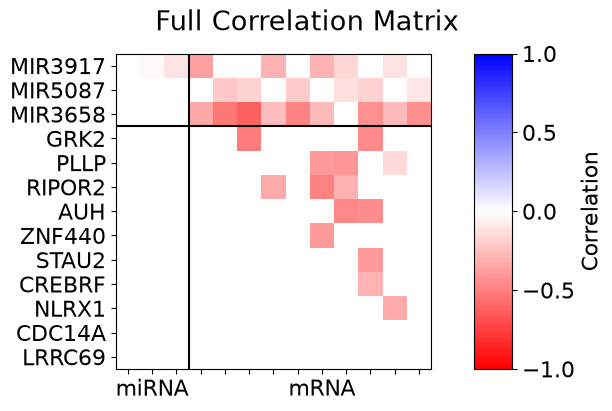

In [320]:
cmap = LinearSegmentedColormap.from_list('a', ['red', 'white', 'blue'])
fig, axs = plt.subplots(1, 2, figsize=(6, 4), gridspec_kw={'width_ratios': [1, 0.1]}, constrained_layout=True)
im = axs[0].imshow(corr_matrix_max, cmap=cmap, vmin=-1, vmax=1)
axs[0].axhline(M - 0.5, color="black")
axs[0].axvline(M - 0.5, color="black")
axs[0].set_yticks(range(S))
axs[0].set_yticklabels(list(miRNA_select) + list(pcRNA_select))
axs[0].set_xticks(range(S))
xlabels = [None for i in range(S)]
xlabels[M // 2] = "miRNA"
xlabels[M + T // 2] = "mRNA"
axs[0].set_xticklabels(xlabels)
fig.suptitle("Full Correlation Matrix")
plt.colorbar(im, cax=axs[1], label="Correlation")
plt.show()

## Heatmap (multi)

In [300]:
# select data
if phase_select == "All":
    adata_select = ad.concat(
        [
            adata_miRNA[:, adata_miRNA.var['GeneName'].isin(miRNA_select)],
            adata_pcRNA[:, adata_pcRNA.var['GeneName'].isin(pcRNA_select)]
        ],
        axis=1
    )
else:
    adata_select = ad.concat(
            [
                adata_miRNA[adata_miRNA.obs['phase'] == phase_select, adata_miRNA.var['GeneName'].isin(miRNA_select)],
                adata_pcRNA[adata_miRNA.obs['phase'] == phase_select, adata_pcRNA.var['GeneName'].isin(pcRNA_select)]
            ],
            axis=1
        )

# settings
d = 3

# compute correlation matrix over all species
gene_queries_multi = [
    [[i for i in range(S)], []]
]

# construct datasets
SDP_data_multi = SDP_miRNA.dataset.Dataset()
SDP_data_multi.construct_dataset_adata(
    adata_select,
    adata_select,
    beta_select,
    gene_queries_multi
)

# bootstrap
SDP_data_multi.bootstrap(d=d)

# model free interacting H&R
MF_int_multi = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data_multi, d=d, HAR=False)
MF_int_multi.analyse_dataset()

corr_matrix_multi = np.zeros((S, S))
for i in range(S):
    for j in range(i + 1, S):
        corr_matrix_multi[i, j] = compute_feasible_correlation(
            MF_int_multi,
            MF_int_multi.feasible_values_optimization_dict[0][0],
            i,
            j,
            MOSEK=True
        )

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  3.20it/s]


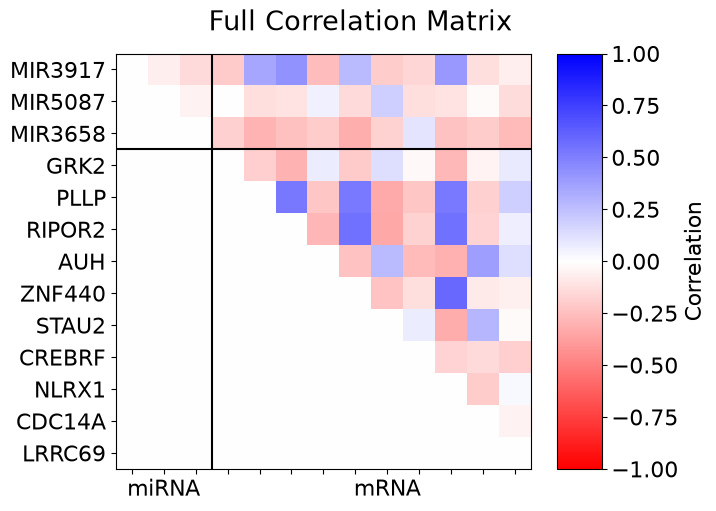

In [316]:
cmap = LinearSegmentedColormap.from_list('a', ['red', 'white', 'blue'])
fig, axs = plt.subplots(1, 2, figsize=(7, 5), gridspec_kw={'width_ratios': [1, 0.1]}, constrained_layout=True)
im = axs[0].imshow(corr_matrix_multi, cmap=cmap, vmin=-1, vmax=1)
axs[0].axhline(M - 0.5, color="black")
axs[0].axvline(M - 0.5, color="black")
axs[0].set_yticks(range(S))
axs[0].set_yticklabels(list(miRNA_select) + list(pcRNA_select))
axs[0].set_xticks(range(S))
xlabels = [None for i in range(S)]
xlabels[M // 2] = "miRNA"
xlabels[M + T // 2] = "mRNA"
axs[0].set_xticklabels(xlabels)
fig.suptitle("Full Correlation Matrix")
plt.colorbar(im, cax=axs[1], label="Correlation")
plt.show()

## Diagram

In [ ]:
# Diagram of miRNA - mRNA network

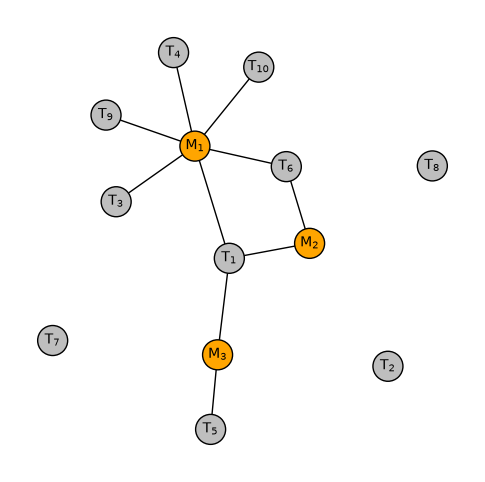

In [447]:
edges = []
for i in range(M):
    size_i = int(rng.poisson(T // 3))
    targets_i = rng.choice(T, size=size_i, replace=False)
    edges_i = [(i, M + int(j)) for j in targets_i]
    edges += list(edges_i)

edge_width = [1 for e in edges]
edge_color = ["black" for e in edges]

vertices = S
vertex_color = ["orange"] * M + ["grey"] * T
vertex_size = [30] * M + [30] * T
vertex_label = [fr"M$_{{{i + 1}}}$" for i in range(M)] + [fr"T$_{{{i + 1}}}$" for i in range(T)]

# construct graph
g = ig.Graph(vertices, edges, directed=False)

fig, axs = plt.subplots(figsize=(6, 6))
        
ig.plot(
    g,
    target=axs,
    #layout="large", # node layout algorithm
    vertex_size=vertex_size,
    vertex_color=vertex_color,
    vertex_frame_width=1,
    vertex_label=vertex_label,
    vertex_label_size=10,
    edge_width=edge_width,
    edge_color=edge_color,
    #edge_label=["⊣" for e in edges]
)

## Model

In [ ]:
# Latex of miRNA - mRNA network model